# Notebook 10 — Xu et al. contextual comparison using the best same-gene proxy separately in each external cohort

This version selects the highest-performing same-gene proxy **independently in each of the 20 external cohorts** from Raw, CCLE-trained Z-score, and CCLE-trained Linear proxy summaries exported by notebook 08.

The per-cohort proxy selection uses the cohort-level **mean protein-wise Pearson correlation**. The three proxy variants can have slightly different numbers of valid protein-wise correlations after all availability/finite-metric restrictions; this notebook reports those counts but does not abort. Therefore the selected proxy panel is an explicitly descriptive, optimistic upper-envelope sensitivity analysis rather than a strictly matched-protein head-to-head comparison.

ElasticNet and XGBoost remain frozen and are compared with Xu Table S6 predictive-model `r`; the selected same-gene proxy is compared with Xu Table S6 same-gene `pearson`.


In [4]:
# >>> pRNA figure routing (added by the pRNA update; keep as the first code cell)
# Every figure is shown inline. Every file written with savefig (png, pdf, svg) is redirected to
# figures_pdf/<notebook name>/ next to this notebook; sub-folders of the original path are preserved.
import os as _fig_os
from pathlib import Path as _FigPath
import matplotlib as _fig_mpl
import matplotlib.pyplot as _fig_plt
from matplotlib.figure import Figure as _FigFigure

NOTEBOOK_NAME = "10_xu_contextual_comparison"
FIG_DIR = (_FigPath.cwd() / "figures_pdf" / NOTEBOOK_NAME).resolve()
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _route_figure_path(fname):
    p = _FigPath(_fig_os.fspath(fname))
    full = p if p.is_absolute() else (_FigPath.cwd() / p)
    try:
        full.resolve().relative_to(FIG_DIR)
        return fname                                  # already inside this notebook's figure folder
    except ValueError:
        pass
    try:
        rel = _FigPath(_fig_os.path.relpath(full.resolve(), _FigPath.cwd()))
    except ValueError:                                # e.g. another drive on Windows
        rel = _FigPath(p.name)
    parts = [x for x in rel.parts if x not in ("..", ".", "figures_pdf", NOTEBOOK_NAME)]
    target = FIG_DIR.joinpath(*parts) if parts else FIG_DIR / p.name
    target.parent.mkdir(parents=True, exist_ok=True)
    return target


if not getattr(_FigFigure.savefig, "_prna_routed", False):
    _fig_orig_savefig = _FigFigure.savefig

    def _fig_routed_savefig(self, fname, *args, **kwargs):
        if isinstance(fname, (str, bytes, _FigPath)) or hasattr(fname, "__fspath__"):
            fname = _route_figure_path(fname)
        return _fig_orig_savefig(self, fname, *args, **kwargs)

    _fig_routed_savefig._prna_routed = True
    _FigFigure.savefig = _fig_routed_savefig

    _fig_orig_close = _fig_plt.close

    def _fig_close_and_show(fig=None):
        """Display figures that are closed before Jupyter could render them, then close."""
        import inspect as _fig_inspect
        _caller = _fig_inspect.currentframe().f_back
        _caller_mod = (_caller.f_globals.get("__name__", "") if _caller is not None else "")
        if _caller_mod.startswith(("matplotlib", "ipykernel")):   # backend housekeeping, not user code
            return _fig_orig_close(fig)
        if "inline" in str(_fig_mpl.get_backend()).lower():
            from IPython.display import display as _fig_display
            open_nums = set(_fig_plt.get_fignums())
            if fig is None:
                figs = [_fig_plt.gcf()] if open_nums else []
            elif isinstance(fig, str) and fig == "all":
                figs = [_fig_plt.figure(n) for n in sorted(open_nums)]
            elif isinstance(fig, _FigFigure):
                figs = [fig] if getattr(fig, "number", None) in open_nums else []
            elif isinstance(fig, int):
                figs = [_fig_plt.figure(fig)] if fig in open_nums else []
            else:
                figs = []
            for _f in figs:
                if not getattr(_f, "_prna_displayed", False):
                    _f._prna_displayed = True
                    _fig_display(_f)
        return _fig_orig_close(fig)

    _fig_plt.close = _fig_close_and_show

    _fig_orig_show = _fig_plt.show

    def _fig_show_and_mark(*args, **kwargs):
        for _n in _fig_plt.get_fignums():                    # shown now -> never re-displayed on close
            _fig_plt.figure(_n)._prna_displayed = True
        return _fig_orig_show(*args, **kwargs)

    _fig_plt.show = _fig_show_and_mark

print("Figures are saved to", FIG_DIR)

Figures are saved to C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\notebooks\figures_pdf\10_xu_contextual_comparison


In [5]:
from pathlib import Path
import json
import os
import re
import sys
import warnings

# Bound numerical-library threading before importing numpy/pandas.
for _thread_var in (
    "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
    "NUMEXPR_NUM_THREADS", "VECLIB_MAXIMUM_THREADS",
):
    os.environ.setdefault(_thread_var, "1")

# Find the shared module whether the kernel starts in project root, notebooks/, notebooks2/,
# or the delivered notebook directory.
search_roots = []
if os.environ.get("PAPER_VALIDATION_MODULE_DIR"):
    search_roots.append(Path(os.environ["PAPER_VALIDATION_MODULE_DIR"]).expanduser().resolve())

cwd = Path.cwd().resolve()
for base in [cwd, *cwd.parents]:
    for candidate in [base, base / "paper_ready_external_validation", base / "notebooks", base / "notebooks2"]:
        if candidate not in search_roots:
            search_roots.append(candidate)

for candidate in search_roots:
    if (candidate / "paper_validation.py").exists():
        sys.path.insert(0, str(candidate))
        MODULE_DIR = candidate
        break
else:
    raise FileNotFoundError(
        "paper_validation.py was not found. Keep it beside this notebook or set "
        "PAPER_VALIDATION_MODULE_DIR to its directory."
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

import paper_validation as pv

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

PROJECT_ROOT = pv.detect_project_root()
RUN_ROOT = Path(os.environ.get(
    "PAPER_VALIDATION_RUN_ROOT",
    PROJECT_ROOT / "results_external_validation_paper_v1",
)).expanduser().resolve()
LAYOUT = pv.make_output_layout(RUN_ROOT)
MANIFEST_PATH = RUN_ROOT / "validation_manifest.json"
SMOKE_TEST = os.environ.get("PAPER_VALIDATION_SMOKE_TEST", "0") == "1"

print("Notebook 10 — Xu contextual comparison")
print("Shared module:", MODULE_DIR / "paper_validation.py")
print("Project root:", PROJECT_ROOT)
print("Run root:", RUN_ROOT)
print("Smoke-test mode:", SMOKE_TEST)


Notebook 10 — Xu contextual comparison
Shared module: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\notebooks\paper_validation.py
Project root: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation
Run root: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\results_external_validation_paper_v1
Smoke-test mode: False


## 1. Load the frozen cohort summaries and Xu Table S6

ElasticNet/XGBoost are taken from notebook 08's frozen `primary_raw` cohort summary. Raw, Z-score, and Linear proxy variants are taken from the auxiliary `external_proxy_variant_cohort_summary` exported by the corrected notebook 08.

Both tables must carry the same single frozen result-manifest hash. A newer `validation_manifest.json` is reported separately and does not silently relabel the older frozen results. Set `PAPER_VALIDATION_STRICT_MANIFEST_MATCH=1` for fail-fast behavior against the current manifest.

In [6]:
# -----------------------------------------------------------------------------
# Load frozen notebook-08 tables. Their embedded result hash is authoritative.
# -----------------------------------------------------------------------------
try:
    manifest = pv.load_manifest(MANIFEST_PATH)
    CURRENT_MANIFEST_HASH = str(manifest["manifest_hash"])
except Exception as exc:
    manifest = None
    CURRENT_MANIFEST_HASH = None
    warnings.warn(
        "Current validation_manifest.json could not be loaded. The frozen notebook-08 result hash "
        f"will still be used for provenance. Details: {type(exc).__name__}: {exc}"
    )

cohort_summary = pv.read_table(LAYOUT["tables"] / "external_cohort_primary_summary")
try:
    proxy_variant_summary = pv.read_table(LAYOUT["tables"] / "external_proxy_variant_cohort_summary")
except Exception as exc:
    raise RuntimeError(
        "external_proxy_variant_cohort_summary is missing. Run "
        "08_plots_paper_ready_best_proxy_support_robust.ipynb from the top first."
    ) from exc

required_local = {"cohort", "model", "matched_proteins", "mean_pearson", "external_samples", "manifest_hash"}
missing_local = sorted(required_local.difference(cohort_summary.columns))
if missing_local:
    raise RuntimeError("external_cohort_primary_summary is missing columns: " + str(missing_local))
proxy_required = {"cohort", "model", "matched_proteins", "mean_pearson", "external_samples", "manifest_hash"}
proxy_missing = sorted(proxy_required.difference(proxy_variant_summary.columns))
if proxy_missing:
    raise RuntimeError("external_proxy_variant_cohort_summary is missing columns: " + str(proxy_missing))

local_hashes = sorted(cohort_summary["manifest_hash"].dropna().astype(str).unique().tolist())
proxy_hashes = sorted(proxy_variant_summary["manifest_hash"].dropna().astype(str).unique().tolist())
if len(local_hashes) != 1:
    raise RuntimeError(
        "external_cohort_primary_summary does not represent one frozen validation run: " + str(local_hashes)
    )
if proxy_hashes != local_hashes:
    raise RuntimeError(
        "Primary and all-proxy notebook-08 tables were generated from different result runs. "
        f"primary={local_hashes}, proxy={proxy_hashes}. Re-run corrected notebook 08 from the top."
    )

RESULT_MANIFEST_HASH = local_hashes[0]
MANIFEST_HASH = RESULT_MANIFEST_HASH
MANIFEST_MATCHES_CURRENT = CURRENT_MANIFEST_HASH is not None and RESULT_MANIFEST_HASH == CURRENT_MANIFEST_HASH
STRICT_MANIFEST_MATCH = os.environ.get("PAPER_VALIDATION_STRICT_MANIFEST_MATCH", "0") == "1"

if CURRENT_MANIFEST_HASH is not None and not MANIFEST_MATCHES_CURRENT:
    _manifest_msg = (
        "Current validation_manifest.json differs from the frozen notebook-08 result tables. "
        "Notebook 010 will keep the frozen result provenance. "
        f"current={CURRENT_MANIFEST_HASH}, result={RESULT_MANIFEST_HASH}."
    )
    if STRICT_MANIFEST_MATCH:
        raise RuntimeError(_manifest_msg)
    warnings.warn(_manifest_msg, RuntimeWarning)
    print("WARNING:", _manifest_msg)

print("Current manifest hash:", CURRENT_MANIFEST_HASH)
print("Frozen result manifest hash:", RESULT_MANIFEST_HASH)
print("Using result hash for notebook-010 outputs:", MANIFEST_HASH)

if "scenario" in cohort_summary.columns:
    cohort_summary = cohort_summary[cohort_summary["scenario"].astype(str).eq("primary_raw")].copy()
if "scenario" in proxy_variant_summary.columns:
    proxy_variant_summary = proxy_variant_summary[
        proxy_variant_summary["scenario"].astype(str).eq("primary_raw")
    ].copy()

# Locate Xu workbook.
XU_CANDIDATES = []
if os.environ.get("XU_XLSX_PATH"):
    XU_CANDIDATES.append(Path(os.environ["XU_XLSX_PATH"]).expanduser())
XU_CANDIDATES += [
    PROJECT_ROOT / "Table0_S1-S8_Combined20220114.xlsx",
    PROJECT_ROOT / "data" / "Table0_S1-S8_Combined20220114.xlsx",
    PROJECT_ROOT / "processed_data" / "Table0_S1-S8_Combined20220114.xlsx",
]
xu_path = next((p for p in XU_CANDIDATES if p.exists() and p.stat().st_size > 0), None)
if xu_path is None:
    raise FileNotFoundError(
        "Xu workbook not found. Set XU_XLSX_PATH or place Table0_S1-S8_Combined20220114.xlsx "
        "in the project root."
    )

xl = pd.ExcelFile(xu_path)
xu_sheet = next((s for s in ("TableS6", "Table S6", "S6") if s in xl.sheet_names), None)
if xu_sheet is None:
    raise RuntimeError(f"TableS6 sheet not found; available sheets={xl.sheet_names}")

xu_raw = pd.read_excel(xu_path, sheet_name=xu_sheet)
rename = {}
for column in xu_raw.columns:
    key = re.sub(r"[^a-z0-9]+", "", str(column).lower())
    if key == "shortname":
        rename[column] = "xu_shortname"
    elif key == "pearson":
        rename[column] = "xu_proxy_pearson"
    elif key in {"r", "correlation"}:
        rename[column] = "xu_model_r"
    elif key == "rmse":
        rename[column] = "xu_rmse"
    elif key == "samples":
        rename[column] = "xu_samples"
    elif key == "common":
        rename[column] = "xu_common"

xu = xu_raw.rename(columns=rename).copy()
required_xu = ["xu_shortname", "xu_proxy_pearson", "xu_model_r"]
missing_xu = [c for c in required_xu if c not in xu.columns]
if missing_xu:
    raise RuntimeError(f"Xu Table S6 misses required columns: {missing_xu}")

xu["xu_shortname"] = xu["xu_shortname"].astype(str).str.strip()
for col in ["xu_proxy_pearson", "xu_model_r", "xu_rmse", "xu_samples", "xu_common"]:
    if col not in xu.columns:
        xu[col] = np.nan
    xu[col] = pd.to_numeric(xu[col], errors="coerce")

if xu["xu_shortname"].duplicated().any():
    dup = xu.loc[xu["xu_shortname"].duplicated(False), "xu_shortname"].tolist()
    raise RuntimeError(f"Duplicated Xu Table S6 short names: {dup}")

expected_shortnames = set(pv.COHORT_TABLE["xu_shortname"].astype(str))
missing_rows = sorted(expected_shortnames.difference(set(xu["xu_shortname"])))
if missing_rows:
    raise RuntimeError(f"Xu workbook misses expected Table S6 rows: {missing_rows}")

print("Xu workbook:", xu_path)
print("Xu sheet:", xu_sheet)
print("Xu rows available:", len(xu))


Current manifest hash: 98cdc5451b903c1769428a4757a2859815a411310b36efcb7ddbbf347f2bce50
Frozen result manifest hash: 98cdc5451b903c1769428a4757a2859815a411310b36efcb7ddbbf347f2bce50
Using result hash for notebook-010 outputs: 98cdc5451b903c1769428a4757a2859815a411310b36efcb7ddbbf347f2bce50
Xu workbook: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\data\Table0_S1-S8_Combined20220114.xlsx
Xu sheet: TableS6
Xu rows available: 20


## 2. Select the best same-gene proxy separately in every cohort and build the collision-safe 20-cohort table

For cohort $d$, the selected proxy is

$$p_d^*=\arg\max_{p\in\{\mathrm{Raw},\mathrm{Zscore},\mathrm{Linear}\}} \bar r_{p,d},$$

where $\bar r_{p,d}$ is the mean of the finite protein-wise Pearson correlations available for proxy $p$ in cohort $d$. Notebook 08 already restricts rows to the paper matched-primary universe, but the number of finite/available proxy proteins can differ slightly among proxy formulations. Those counts are audited below and are **not** treated as an execution error.


In [7]:
# -----------------------------------------------------------------------------
# Canonical model labels and per-cohort best-of-three proxy selection.
# -----------------------------------------------------------------------------
def _canonical_model_name(value):
    text = str(value).strip()
    key = re.sub(r"[^a-z0-9]+", "", text.lower())
    if key in {"elasticnet", "enet"} or "elasticnet" in key:
        return "ElasticNet"
    if key in {"xgboost", "xgb"} or "xgboost" in key:
        return "XGBoost"
    if key in {"rawproxy", "rawsamegeneproxy"} or ("proxy" in key and "raw" in key):
        return "RawProxy"
    if key in {"zscoreproxy", "zscoresamegeneproxy"} or ("proxy" in key and "zscore" in key):
        return "ZscoreProxy"
    if key in {"linearproxy", "samegenelinearproxy"} or ("proxy" in key and ("linear" in key or "regression" in key)):
        return "LinearProxy"
    return text

PROXY_CANDIDATES = ["RawProxy", "ZscoreProxy", "LinearProxy"]
PROXY_LABELS = {
    "RawProxy": "Raw same-gene proxy",
    "ZscoreProxy": "Z-score same-gene proxy",
    "LinearProxy": "Same-gene linear proxy",
}
# Deterministic tie-break only for exactly equal cohort-level mean Pearson values.
PROXY_TIE_BREAK_ORDER = {"RawProxy": 0, "ZscoreProxy": 1, "LinearProxy": 2}
BEST_PROXY_PER_COHORT_MODEL = "BestProxyPerCohort"
BEST_PROXY_PER_COHORT_LABEL = "Best proxy per cohort"
EXPECTED_COHORTS = int(len(pv.COHORT_TABLE))

cohort_summary = cohort_summary.copy()
cohort_summary["model_canonical"] = cohort_summary["model"].map(_canonical_model_name)
cohort_summary["mean_pearson"] = pd.to_numeric(cohort_summary["mean_pearson"], errors="coerce")

proxy_variant_summary = proxy_variant_summary.copy()
proxy_variant_summary["model_canonical"] = proxy_variant_summary["model"].map(_canonical_model_name)
proxy_variant_summary["mean_pearson"] = pd.to_numeric(proxy_variant_summary["mean_pearson"], errors="coerce")

# One and only one row per proxy variant/cohort must come from notebook 08.
proxy_rows = proxy_variant_summary[
    proxy_variant_summary["model_canonical"].isin(PROXY_CANDIDATES)
].copy()
if proxy_rows.duplicated(["cohort", "model_canonical"], keep=False).any():
    bad = proxy_rows.loc[
        proxy_rows.duplicated(["cohort", "model_canonical"], keep=False),
        ["cohort", "model", "model_canonical", "mean_pearson"],
    ]
    raise RuntimeError("Duplicated proxy cohort summaries from notebook 08:\n" + bad.to_string(index=False))

proxy_rows["proxy_model"] = proxy_rows["model_canonical"]
proxy_rows["proxy_label"] = proxy_rows["proxy_model"].map(PROXY_LABELS)
proxy_rows["tie_break_rank"] = proxy_rows["proxy_model"].map(PROXY_TIE_BREAK_ORDER)

# Require all three finite proxy values in every one of the 20 cohorts.
proxy_cohort_coverage = (
    proxy_rows.groupby("cohort", observed=True)
    .agg(
        proxy_variants=("proxy_model", "nunique"),
        finite_proxy_variants=("mean_pearson", lambda s: int(pd.to_numeric(s, errors="coerce").notna().sum())),
        matched_protein_count_versions=("matched_proteins", "nunique"),
        min_matched_proteins=("matched_proteins", "min"),
        max_matched_proteins=("matched_proteins", "max"),
    )
    .reset_index()
)
proxy_cohort_coverage["matched_protein_count_range"] = (
    pd.to_numeric(proxy_cohort_coverage["max_matched_proteins"], errors="coerce")
    - pd.to_numeric(proxy_cohort_coverage["min_matched_proteins"], errors="coerce")
)
expected_cohort_names = set(pv.COHORT_TABLE["cohort"].astype(str))
observed_cohort_names = set(proxy_cohort_coverage["cohort"].astype(str))
if observed_cohort_names != expected_cohort_names:
    missing = sorted(expected_cohort_names - observed_cohort_names)
    extra = sorted(observed_cohort_names - expected_cohort_names)
    raise RuntimeError(f"Proxy cohort coverage mismatch. Missing={missing}, extra={extra}")
if not proxy_cohort_coverage["proxy_variants"].eq(3).all():
    raise RuntimeError(
        "Each cohort must contain Raw, Z-score, and Linear proxy rows.\n"
        + proxy_cohort_coverage.to_string(index=False)
    )
if not proxy_cohort_coverage["finite_proxy_variants"].eq(3).all():
    raise RuntimeError(
        "Each cohort must contain three finite cohort-level proxy Pearson values.\n"
        + proxy_cohort_coverage.to_string(index=False)
    )
different_proxy_counts = proxy_cohort_coverage["matched_protein_count_versions"].gt(1)
if different_proxy_counts.any():
    warnings.warn(
        "Raw/Z-score/Linear proxy summaries have different valid protein counts in one or more cohorts. "
        "Per-cohort selection will still be performed on the notebook-08 cohort-level mean Pearson values, "
        "but this makes the selected-proxy panel an optimistic descriptive upper envelope rather than a "
        "strictly identical-protein comparison. Inspect proxy_cohort_coverage and the selection audit for counts."
    )

print("Proxy candidate coverage by cohort (count differences are diagnostic, not fatal):")
display(proxy_cohort_coverage.sort_values("cohort").reset_index(drop=True))

# Global candidate summary is retained only as a diagnostic; it does NOT drive selection.
proxy_candidate_summary = (
    proxy_rows.groupby("proxy_model", observed=True)
    .agg(
        cohorts=("cohort", "nunique"),
        mean_cohort_pearson=("mean_pearson", "mean"),
        median_cohort_pearson=("mean_pearson", "median"),
        min_cohort_pearson=("mean_pearson", "min"),
        max_cohort_pearson=("mean_pearson", "max"),
    )
    .reindex(PROXY_CANDIDATES)
    .reset_index()
)
proxy_candidate_summary["proxy_label"] = proxy_candidate_summary["proxy_model"].map(PROXY_LABELS)
proxy_candidate_summary["manifest_hash"] = MANIFEST_HASH
proxy_candidate_summary_path = pv.write_table(
    proxy_candidate_summary,
    LAYOUT["xu"] / "xu_proxy_candidate_global_diagnostic",
    index=False,
)

# Select the best proxy independently within each cohort.
proxy_ranked = proxy_rows.sort_values(
    ["cohort", "mean_pearson", "tie_break_rank"],
    ascending=[True, False, True],
).copy()
selected_proxy_local = (
    proxy_ranked.groupby("cohort", observed=True, sort=False)
    .head(1)
    .copy()
)
if selected_proxy_local["cohort"].nunique() != EXPECTED_COHORTS:
    raise RuntimeError(
        f"Expected one selected proxy for {EXPECTED_COHORTS} cohorts, found "
        f"{selected_proxy_local['cohort'].nunique()}."
    )

selected_pairs = set(zip(selected_proxy_local["cohort"].astype(str), selected_proxy_local["proxy_model"].astype(str)))
proxy_selection_audit = proxy_ranked.copy()
proxy_selection_audit["selected"] = [
    (str(c), str(m)) in selected_pairs
    for c, m in zip(proxy_selection_audit["cohort"], proxy_selection_audit["proxy_model"])
]
proxy_selection_audit["manifest_hash"] = MANIFEST_HASH
proxy_selection_path = pv.write_table(
    proxy_selection_audit,
    LAYOUT["xu"] / "xu_best_proxy_per_cohort_selection_audit",
    index=False,
)

proxy_selection_counts = (
    selected_proxy_local.groupby(["proxy_model", "proxy_label"], observed=True)
    .agg(
        selected_cohorts=("cohort", "nunique"),
        mean_selected_pearson=("mean_pearson", "mean"),
        median_selected_pearson=("mean_pearson", "median"),
    )
    .reindex(pd.MultiIndex.from_tuples(
        [(m, PROXY_LABELS[m]) for m in PROXY_CANDIDATES],
        names=["proxy_model", "proxy_label"],
    ))
    .fillna({"selected_cohorts": 0})
    .reset_index()
)
proxy_selection_counts["selected_cohorts"] = proxy_selection_counts["selected_cohorts"].astype(int)
proxy_selection_counts["manifest_hash"] = MANIFEST_HASH
proxy_selection_counts_path = pv.write_table(
    proxy_selection_counts,
    LAYOUT["xu"] / "xu_best_proxy_per_cohort_counts",
    index=False,
)

print("Best same-gene proxy selected separately within each external cohort.")
print("Selection criterion: highest cohort-level mean protein-wise Pearson.")
display(selected_proxy_local[["cohort", "proxy_model", "proxy_label", "mean_pearson", "matched_proteins"]].sort_values("cohort"))
print("\nHow often each proxy variant was selected:")
display(proxy_selection_counts)
warnings.warn(
    "The proxy variant is selected separately in each external cohort using the same outcome data shown below. "
    "This is an optimistic per-cohort upper envelope and must be interpreted as a descriptive sensitivity analysis; "
    "in some cohorts the three proxy summaries also contain different numbers of valid protein-wise correlations. "
    "ElasticNet and XGBoost remain frozen and are not selected on external performance."
)

# -----------------------------------------------------------------------------
# Build per-cohort best proxy + fixed ElasticNet + fixed XGBoost comparison table.
# -----------------------------------------------------------------------------
MODEL_ORDER = [BEST_PROXY_PER_COHORT_MODEL, "ElasticNet", "XGBoost"]
MODEL_LABELS = {
    BEST_PROXY_PER_COHORT_MODEL: BEST_PROXY_PER_COHORT_LABEL,
    "ElasticNet": "ElasticNet",
    "XGBoost": "XGBoost",
}

# Preserve the identity of the proxy variant chosen in each cohort, then expose the
# selected rows as one synthetic model for consistent downstream plotting.
selected_proxy_local["selected_proxy_model"] = selected_proxy_local["proxy_model"]
selected_proxy_local["selected_proxy_label"] = selected_proxy_local["proxy_label"]
selected_proxy_local["model_canonical"] = BEST_PROXY_PER_COHORT_MODEL
selected_proxy_local["model"] = BEST_PROXY_PER_COHORT_MODEL

multigene_local = cohort_summary[
    cohort_summary["model_canonical"].isin(["ElasticNet", "XGBoost"])
].copy()
multigene_local["model"] = multigene_local["model_canonical"]
local = pd.concat([selected_proxy_local, multigene_local], ignore_index=True, sort=False)

if local.duplicated(["cohort", "model"], keep=False).any():
    bad = local.loc[
        local.duplicated(["cohort", "model"], keep=False),
        ["cohort", "model", "mean_pearson"],
    ]
    raise RuntimeError("Duplicated cohort/model rows after per-cohort proxy selection:\n" + bad.to_string(index=False))

cohort_lookup = pv.COHORT_TABLE[["cohort", "platform", "xu_shortname"]].copy()
cohort_lookup["cohort"] = cohort_lookup["cohort"].astype(str)
if cohort_lookup["cohort"].duplicated().any():
    raise RuntimeError("COHORT_TABLE contains duplicated cohort identifiers.")

local = local.drop(columns=["platform", "xu_shortname"], errors="ignore")
local = local.merge(cohort_lookup, on="cohort", how="inner", validate="many_to_one")

xu_reference = xu[[
    "xu_shortname", "xu_proxy_pearson", "xu_model_r", "xu_rmse", "xu_samples", "xu_common"
]].copy()
matched = local.merge(xu_reference, on="xu_shortname", how="left", validate="many_to_one")

for forbidden in ("platform_x", "platform_y"):
    if forbidden in matched.columns:
        raise RuntimeError(f"Unexpected merge collision created {forbidden!r}.")
if "platform" not in matched.columns:
    raise RuntimeError("Local platform column was lost during the Xu merge.")

is_proxy = matched["model"].eq(BEST_PROXY_PER_COHORT_MODEL)
matched["model_label"] = matched["model"].map(MODEL_LABELS)
matched["xu_reference"] = np.where(is_proxy, matched["xu_proxy_pearson"], matched["xu_model_r"])
matched["xu_reference_name"] = np.where(is_proxy, "Xu same-gene Pearson", "Xu predictive-model r")
matched["comparison_type"] = np.where(is_proxy, "per-cohort best-of-three same-gene proxy", "predictive model")
matched["local_statistic"] = pd.to_numeric(matched["mean_pearson"], errors="coerce")
matched["descriptive_difference"] = matched["local_statistic"] - matched["xu_reference"]
matched["manifest_hash"] = MANIFEST_HASH

# Non-proxy rows keep these fields missing; proxy rows retain the exact chosen variant.
if "selected_proxy_model" not in matched.columns:
    matched["selected_proxy_model"] = pd.NA
if "selected_proxy_label" not in matched.columns:
    matched["selected_proxy_label"] = pd.NA

missing_reference = matched["xu_reference"].isna() | matched["local_statistic"].isna()
if missing_reference.any():
    bad = matched.loc[missing_reference, [
        "cohort", "platform", "xu_shortname", "model", "local_statistic", "xu_reference"
    ]]
    raise RuntimeError("Missing local or Xu comparison values:\n" + bad.to_string(index=False))

coverage = (
    matched.groupby("model", observed=True)["xu_shortname"].nunique()
    .rename("matched_xu_rows").reset_index()
)
coverage["expected_xu_rows"] = EXPECTED_COHORTS
coverage["complete"] = coverage["matched_xu_rows"].eq(EXPECTED_COHORTS)
coverage["manifest_hash"] = MANIFEST_HASH
if not coverage["complete"].all():
    raise RuntimeError("Not every selected model maps to all 20 Xu cohorts.\n" + coverage.to_string(index=False))

mapping_audit = (
    matched.loc[is_proxy, [
        "cohort", "platform", "xu_shortname", "external_samples", "matched_proteins",
        "selected_proxy_model", "selected_proxy_label", "local_statistic",
        "xu_samples", "xu_common",
    ]]
    .drop_duplicates("cohort")
    .copy()
)
mapping_audit = mapping_audit.rename(columns={"local_statistic": "selected_proxy_mean_pearson"})
mapping_audit["sample_count_difference"] = (
    pd.to_numeric(mapping_audit["external_samples"], errors="coerce")
    - pd.to_numeric(mapping_audit["xu_samples"], errors="coerce")
)
mapping_audit["matched_model_universe_minus_xu_common"] = (
    pd.to_numeric(mapping_audit["matched_proteins"], errors="coerce")
    - pd.to_numeric(mapping_audit["xu_common"], errors="coerce")
)
mapping_audit["sample_count_matches_xu"] = mapping_audit["sample_count_difference"].fillna(0).eq(0)
mapping_audit["manifest_hash"] = MANIFEST_HASH

if mapping_audit["cohort"].nunique() != EXPECTED_COHORTS:
    raise RuntimeError(f"Expected {EXPECTED_COHORTS} local cohorts, found {mapping_audit['cohort'].nunique()}.")
if mapping_audit["xu_shortname"].nunique() != EXPECTED_COHORTS:
    raise RuntimeError(f"Expected {EXPECTED_COHORTS} Xu rows, found {mapping_audit['xu_shortname'].nunique()}.")

matched_path = pv.write_table(
    matched,
    LAYOUT["xu"] / "xu_contextual_comparison_20_cohorts_best_proxy_per_cohort",
    index=False,
)
coverage_path = pv.write_table(
    coverage,
    LAYOUT["xu"] / "xu_mapping_coverage_best_proxy_per_cohort",
    index=False,
)
mapping_audit_path = pv.write_table(
    mapping_audit,
    LAYOUT["xu"] / "xu_cohort_mapping_audit_best_proxy_per_cohort",
    index=False,
)

print("\nCoverage audit")
display(coverage)
print("\nPer-cohort selected proxy and Xu mapping audit")
display(mapping_audit.sort_values(["platform", "cohort"]))

sample_mismatches = mapping_audit.loc[~mapping_audit["sample_count_matches_xu"]]
if len(sample_mismatches):
    warnings.warn(
        "Some local sample counts differ from Xu Table S6. The row mapping is retained, "
        "but the Xu comparison remains contextual rather than head-to-head."
    )


Proxy candidate coverage by cohort (count differences are diagnostic, not fatal):


,cohort,proxy_variants,finite_proxy_variants,matched_protein_count_versions,min_matched_proteins,max_matched_proteins,matched_protein_count_range
0,BRAIN,3,3,1,1936,1936,0
1,BRAIN_2021,3,3,1,466,466,0
2,BREAST2020,3,3,1,3351,3351,0
3,BREAST_2016,3,3,1,3599,3599,0
4,COLON,3,3,1,1623,1623,0
5,COLON_2019,3,3,1,3068,3068,0
6,ENDOMET_VAL,3,3,1,2772,2772,0
7,HEADNECK_2021,3,3,1,4058,4058,0
8,LIVER,3,3,1,1727,1727,0
9,LIVER_VAL,3,3,1,3958,3958,0


Best same-gene proxy selected separately within each external cohort.
Selection criterion: highest cohort-level mean protein-wise Pearson.


,cohort,proxy_model,proxy_label,mean_pearson,matched_proteins
1,BRAIN,RawProxy,Raw same-gene proxy,0.150101,1936
4,BRAIN_2021,RawProxy,Raw same-gene proxy,0.512611,466
7,BREAST2020,RawProxy,Raw same-gene proxy,0.429199,3351
11,BREAST_2016,ZscoreProxy,Z-score same-gene proxy,0.464496,3599
14,COLON,ZscoreProxy,Z-score same-gene proxy,0.246951,1623
17,COLON_2019,ZscoreProxy,Z-score same-gene proxy,0.290089,3068
19,ENDOMET_VAL,RawProxy,Raw same-gene proxy,0.491311,2772
23,HEADNECK_2021,ZscoreProxy,Z-score same-gene proxy,0.543032,4058
26,LIVER,ZscoreProxy,Z-score same-gene proxy,0.391472,1727
29,LIVER_VAL,ZscoreProxy,Z-score same-gene proxy,0.422781,3958



How often each proxy variant was selected:


,proxy_model,proxy_label,selected_cohorts,mean_selected_pearson,median_selected_pearson,manifest_hash
0,RawProxy,Raw same-gene proxy,7,0.402230,0.461783,98cdc5451b903c1769428a4757a2859815a411310b36ef...
1,ZscoreProxy,Z-score same-gene proxy,13,0.353552,0.391472,98cdc5451b903c1769428a4757a2859815a411310b36ef...
2,LinearProxy,Same-gene linear proxy,0,NaN,NaN,98cdc5451b903c1769428a4757a2859815a411310b36ef...



Coverage audit


C:\Users\hp\AppData\Local\Temp\ipykernel_21892\1963179345.py:175: UserWarning: The proxy variant is selected separately in each external cohort using the same outcome data shown below. This is an optimistic per-cohort upper envelope and must be interpreted as a descriptive sensitivity analysis; in some cohorts the three proxy summaries also contain different numbers of valid protein-wise correlations. ElasticNet and XGBoost remain frozen and are not selected on external performance.
  warnings.warn(


,model,matched_xu_rows,expected_xu_rows,complete,manifest_hash
0,BestProxyPerCohort,20,20,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...
1,ElasticNet,20,20,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...
2,XGBoost,20,20,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...



Per-cohort selected proxy and Xu mapping audit


,cohort,platform,xu_shortname,external_samples,matched_proteins,selected_proxy_model,selected_proxy_label,selected_proxy_mean_pearson,xu_samples,xu_common,sample_count_difference,matched_model_universe_minus_xu_common,sample_count_matches_xu,manifest_hash
0,BRAIN,LabelFree,BN_labelfree,71,1936,RawProxy,Raw same-gene proxy,0.150101,71,4234,0,-2298,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...
4,COLON,LabelFree,CO_labelfree,86,1623,ZscoreProxy,Z-score same-gene proxy,0.246951,86,2113,0,-490,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...
8,LIVER,LabelFree,LV_labelfree,62,1727,ZscoreProxy,Z-score same-gene proxy,0.391472,62,2315,0,-588,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...
10,LUNG,LabelFree,LU_labelfree,76,1650,ZscoreProxy,Z-score same-gene proxy,0.097743,76,2209,0,-559,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...
17,PROSTATE,LabelFree,PR_labelfree,65,2046,ZscoreProxy,Z-score same-gene proxy,0.241703,65,3445,0,-1399,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...
1,BRAIN_2021,TMT,BN_tmt,108,466,RawProxy,Raw same-gene proxy,0.512611,108,8565,0,-8099,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...
2,BREAST2020,TMT,BR_tmt,122,3351,RawProxy,Raw same-gene proxy,0.429199,122,5698,0,-2347,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...
5,COLON_2019,TMT,CO_tmt,95,3068,ZscoreProxy,Z-score same-gene proxy,0.290089,95,4201,0,-1133,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...
6,ENDOMET_VAL,TMT,EC_tmt,115,2772,RawProxy,Raw same-gene proxy,0.491311,115,5038,0,-2266,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...
7,HEADNECK_2021,TMT,HN_tmt,151,4058,ZscoreProxy,Z-score same-gene proxy,0.543032,151,7250,0,-3192,True,98cdc5451b903c1769428a4757a2859815a411310b36ef...


## 3. Paper-ready plotting helpers

The figures use the same 20-cohort ordering across models. Xu values are rendered in neutral gray; our transferred models use model-specific colors. Platform is indicated by subtle row bands and/or point color.

For the first panel, the plotted value is the **best of Raw/Z-score/Linear within that specific cohort**. The selected variant itself is stored in the exported selection and mapping audits.


In [8]:
# -----------------------------
# Figure style and helpers
# -----------------------------
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 320,
    # Exactly 2x the original notebook typography, with thicker paper-ready primitives.
    "font.size": 23,
    "axes.titlesize": 28,
    "axes.labelsize": 24,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 20,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.linewidth": 2.0,
    "lines.linewidth": 2.8,
    "legend.frameon": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.22,
})

FIG_DPI = 320
MODEL_COLORS = {
    BEST_PROXY_PER_COHORT_MODEL: "#4C78A8",
    "ElasticNet": "#59A14F",
    "XGBoost": "#F28E2B",
}
PLATFORM_COLORS = {
    "TMT": "#4C78A8",
    "iTRAQ": "#E45756",
    "LabelFree": "#72B7B2",
}
PLATFORM_BANDS = {
    "TMT": "#EDF3F8",
    "iTRAQ": "#FBEDEC",
    "LabelFree": "#EEF7F6",
}
XU_COLOR = "#6B6B6B"

FIGURE_DIR = FIG_DIR
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
figure_paths = []

# Exact order from the frozen cohort contract, grouped by platform.
cohort_order = pv.COHORT_TABLE["cohort"].astype(str).tolist()
cohort_rank = {c: i for i, c in enumerate(cohort_order)}
platform_by_cohort = pv.COHORT_TABLE.set_index("cohort")["platform"].astype(str).to_dict()
shortname_by_cohort = pv.COHORT_TABLE.set_index("cohort")["xu_shortname"].astype(str).to_dict()


def _friendly_cohort_label(cohort):
    return f"{str(cohort).replace('_', ' ')}  ·  {shortname_by_cohort[str(cohort)]}"


def _save_figure(fig, stem, title):
    """Write a vector PDF directly; no raster intermediary is created or required."""
    pdf = FIGURE_DIR / f"{stem}.pdf"
    fig.savefig(
        pdf,
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.30,
        facecolor="white",
        metadata={"Creator": pv.PIPELINE_VERSION, "Title": title, "Subject": f"Manifest {MANIFEST_HASH}"},
    )
    if not pdf.exists():
        raise RuntimeError(f"Figure was not written: {pdf}")
    figure_paths.append(pdf)
    return pdf


def _platform_spans(order):
    spans = []
    start = 0
    while start < len(order):
        platform = platform_by_cohort[order[start]]
        stop = start
        while stop + 1 < len(order) and platform_by_cohort[order[stop + 1]] == platform:
            stop += 1
        spans.append((platform, start - 0.5, stop + 0.5))
        start = stop + 1
    return spans


def _apply_platform_bands(ax, order):
    for platform, y0, y1 in _platform_spans(order):
        ax.axhspan(y0, y1, color=PLATFORM_BANDS[platform], alpha=0.55, zorder=0)


def _correlation_limits(frame):
    vals = np.r_[
        pd.to_numeric(frame["local_statistic"], errors="coerce").to_numpy(float),
        pd.to_numeric(frame["xu_reference"], errors="coerce").to_numpy(float),
    ]
    vals = vals[np.isfinite(vals)]
    if not len(vals):
        return (-0.2, 0.8)
    lo = min(-0.05, float(vals.min()) - 0.08)
    hi = max(0.2, float(vals.max()) + 0.08)
    return max(-1.0, lo), min(1.0, hi)


def _bootstrap_mean_ci(values, n_boot=5000, seed=2026):
    """Bootstrap the mean with a shape-safe 2D resampling matrix.

    The returned bootstrap matrix has shape (n_boot, n_observations), so the
    resampled mean is always taken over axis=1. Flattening first also prevents
    accidental DataFrame/column-vector inputs from creating a third dimension.
    """
    arr = np.asarray(values, dtype=float).reshape(-1)
    arr = arr[np.isfinite(arr)]
    if arr.size == 0:
        return np.nan, np.nan, np.nan
    mean = float(arr.mean())
    if arr.size == 1:
        return mean, mean, mean
    n_boot = int(n_boot)
    if n_boot < 1:
        raise ValueError(f"n_boot must be >= 1, got {n_boot}")
    rng = np.random.default_rng(seed)
    draws = rng.choice(arr, size=(n_boot, arr.size), replace=True)
    boot_means = draws.mean(axis=1)
    return mean, float(np.quantile(boot_means, 0.025)), float(np.quantile(boot_means, 0.975))


## 4. Main figure — cohort-level Xu reference versus our transferred models

Each horizontal segment connects the Xu Table S6 reference value to our corresponding external-transfer value for the same cohort. The first panel uses the **best same-gene proxy selected separately within each cohort** and Xu same-gene `pearson`; the second and third panels use the frozen ElasticNet/XGBoost models and Xu predictive-model `r`.

The first panel is therefore a descriptive **per-cohort best-of-three upper envelope**. Its direction and magnitude should not be interpreted as prospective performance of one deployable proxy model.


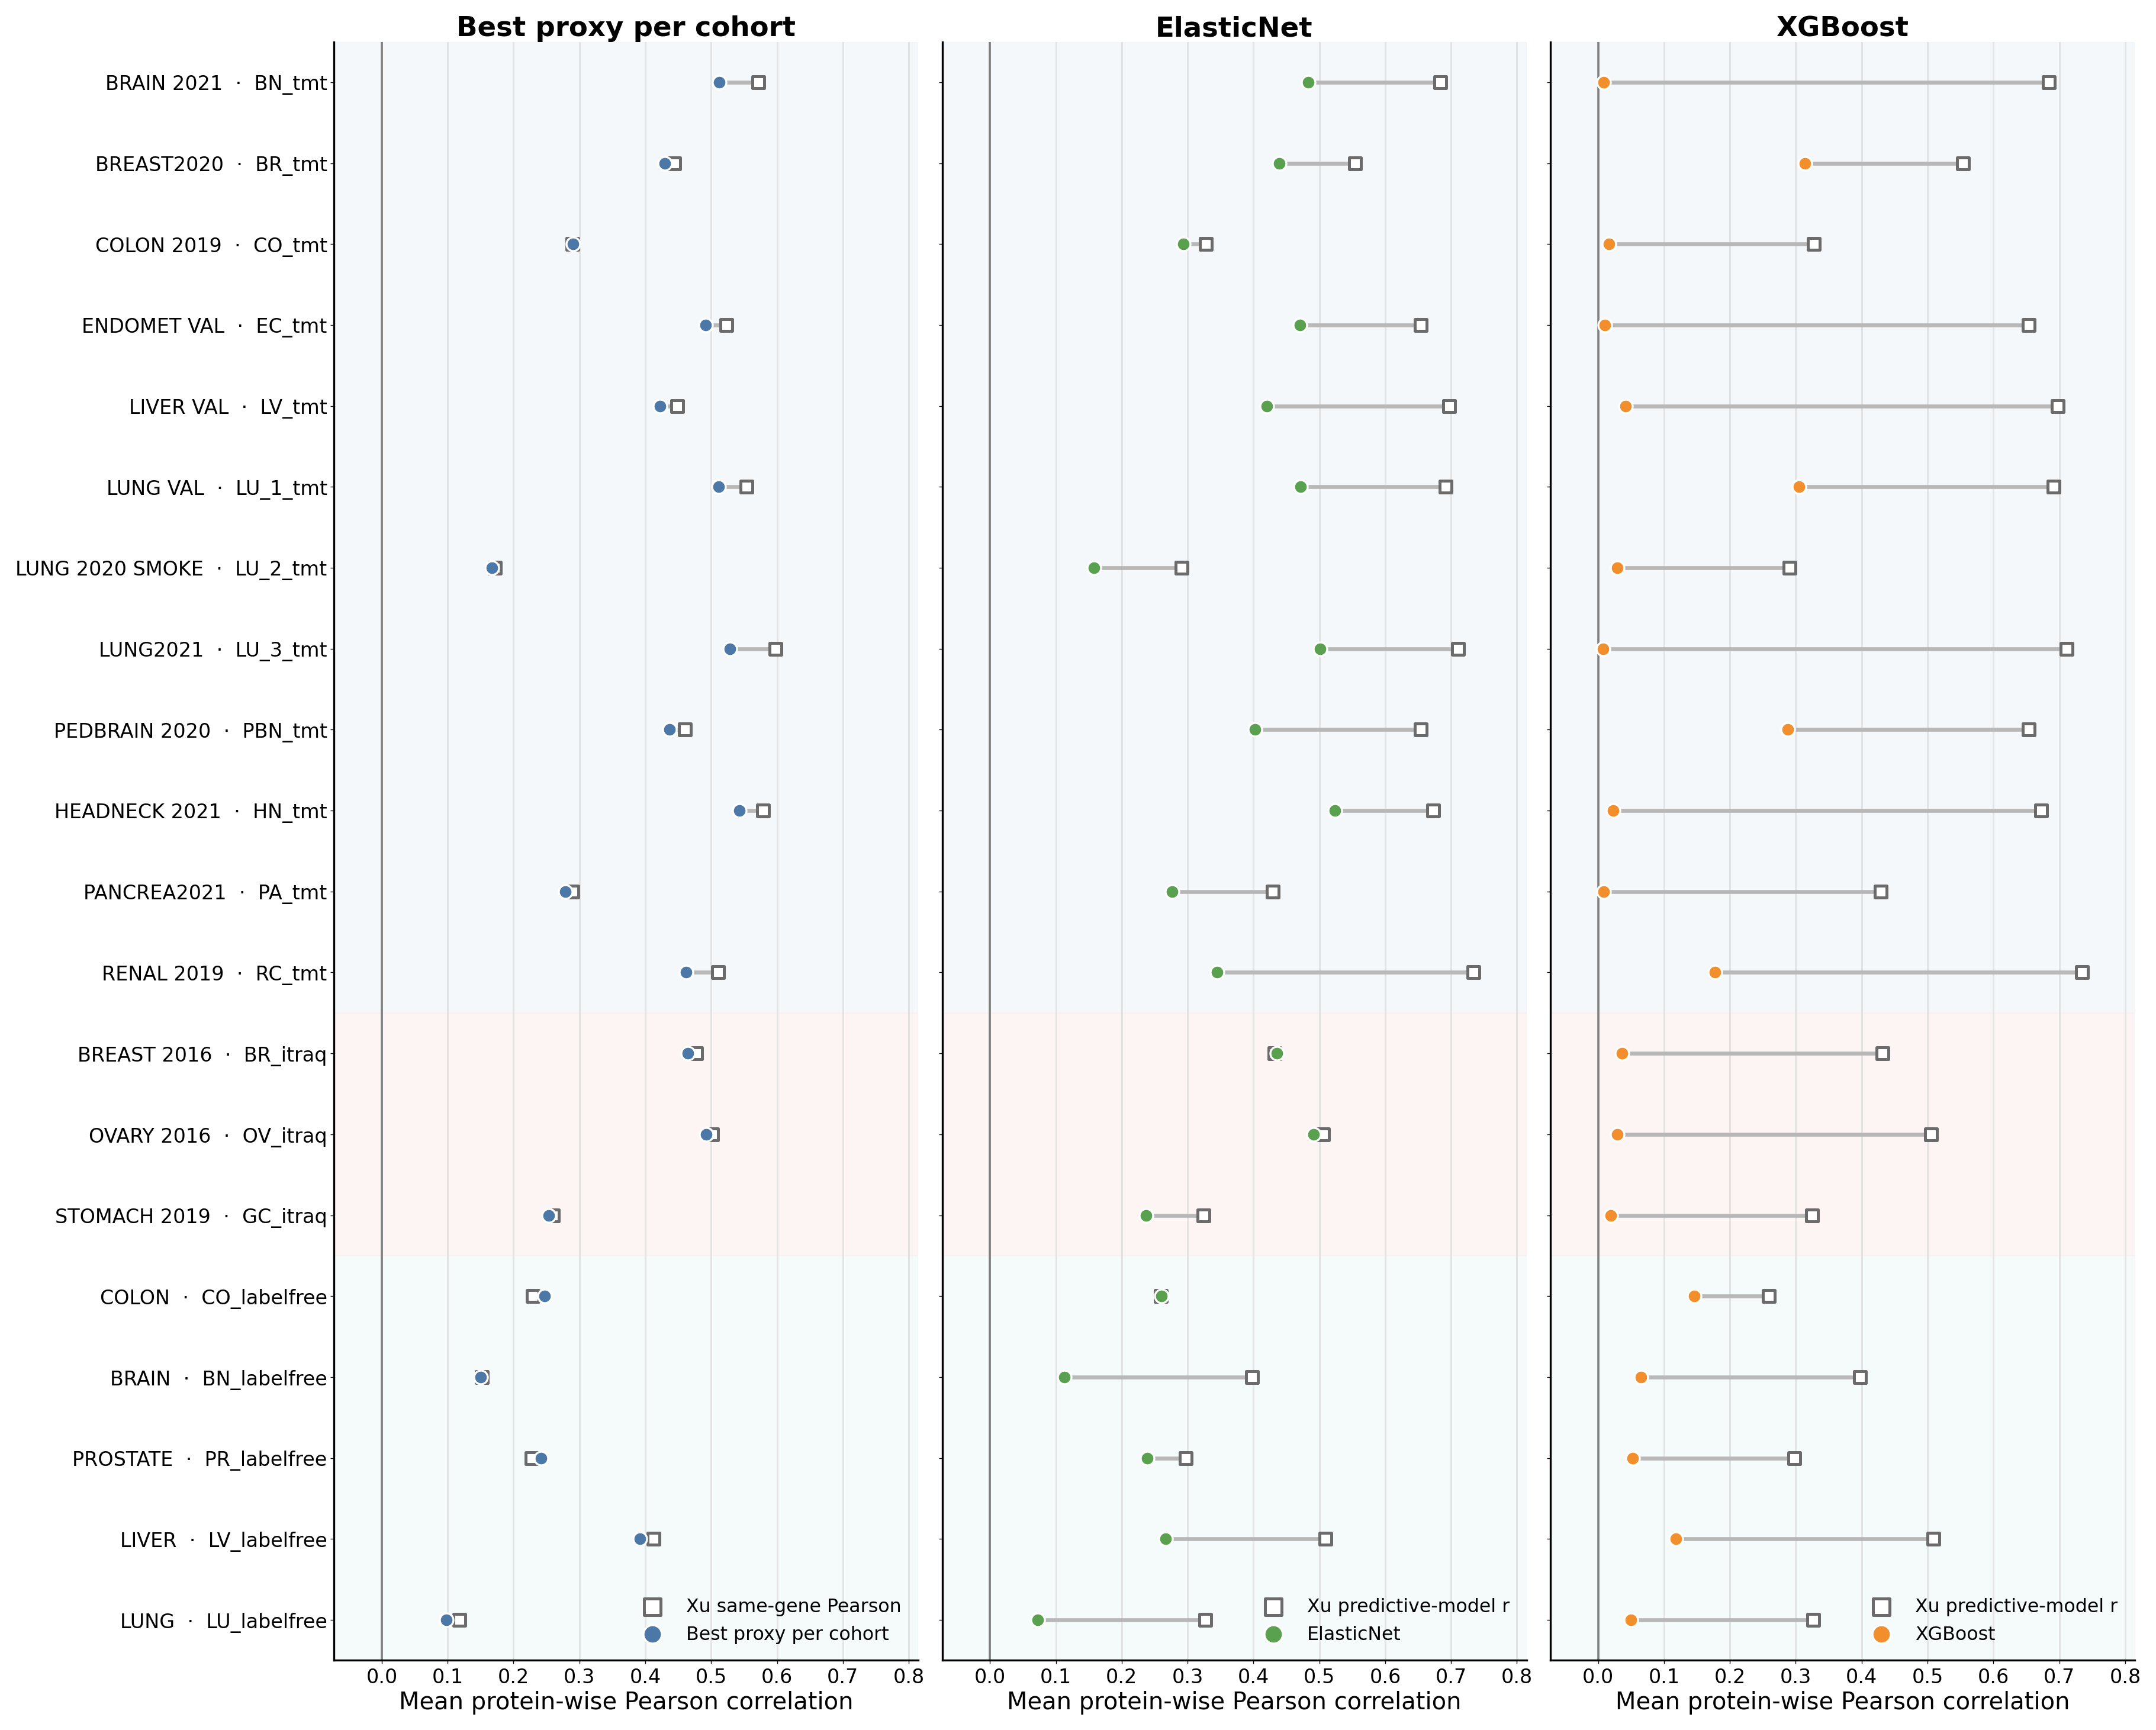

In [9]:
# Figure 1: three-panel dumbbell plot.
plot_frame = matched.copy()
plot_frame["cohort_rank"] = plot_frame["cohort"].map(cohort_rank)
plot_frame = plot_frame.sort_values(["cohort_rank", "model"])

xlim = _correlation_limits(plot_frame)
y = np.arange(len(cohort_order), dtype=float)

fig, axes = plt.subplots(1, 3, figsize=(30.0, 24.0), sharey=True, constrained_layout=True)

for ax, model in zip(axes, MODEL_ORDER):
    sub = (
        plot_frame[plot_frame["model"].eq(model)]
        .set_index("cohort")
        .reindex(cohort_order)
    )
    if sub["local_statistic"].isna().any() or sub["xu_reference"].isna().any():
        raise RuntimeError(f"Missing values after reindexing model {model} to the 20-cohort order.")

    _apply_platform_bands(ax, cohort_order)

    xu_vals = sub["xu_reference"].to_numpy(float)
    our_vals = sub["local_statistic"].to_numpy(float)

    for yi, xu_v, our_v in zip(y, xu_vals, our_vals):
        ax.plot([xu_v, our_v], [yi, yi], color="#B8B8B8", linewidth=4.0, zorder=2)

    ax.scatter(
        xu_vals, y,
        s=150, marker="s", facecolors="white", edgecolors=XU_COLOR,
        linewidths=3.0, label=sub["xu_reference_name"].iloc[0], zorder=4,
    )
    ax.scatter(
        our_vals, y,
        s=190, marker="o", color=MODEL_COLORS[model], edgecolors="white",
        linewidths=2.0, label=MODEL_LABELS[model], zorder=5,
    )

    ax.axvline(0, color="#555555", linewidth=2.2, alpha=0.7)
    ax.set_xlim(*xlim)
    ax.set_ylim(len(cohort_order) - 0.5, -0.5)
    ax.set_xlabel("Mean protein-wise Pearson correlation")
    ax.set_title(MODEL_LABELS[model])
    ax.grid(axis="x", color="#D9D9D9", linewidth=1.8, alpha=0.65)
    ax.legend(loc="lower right", fontsize=19, markerscale=1.35)

axes[0].set_yticks(y)
axes[0].set_yticklabels([_friendly_cohort_label(c) for c in cohort_order], fontsize=20)
for ax in axes[1:]:
    ax.tick_params(axis="y", labelleft=False)

_save_figure(
    fig,
    "figure_external_validation_xu_context",
    "External transfer versus Xu Table S6 with per-cohort best proxy",
)
plt.show()


## 5. Agreement view — Xu reference on the x-axis, our transfer on the y-axis

The diagonal is the identity line. Points are colored by proteomic platform. This view is useful for seeing whether cohorts that are relatively easier/harder in Xu et al. are also relatively easier/harder for the frozen CCLE transfer models.


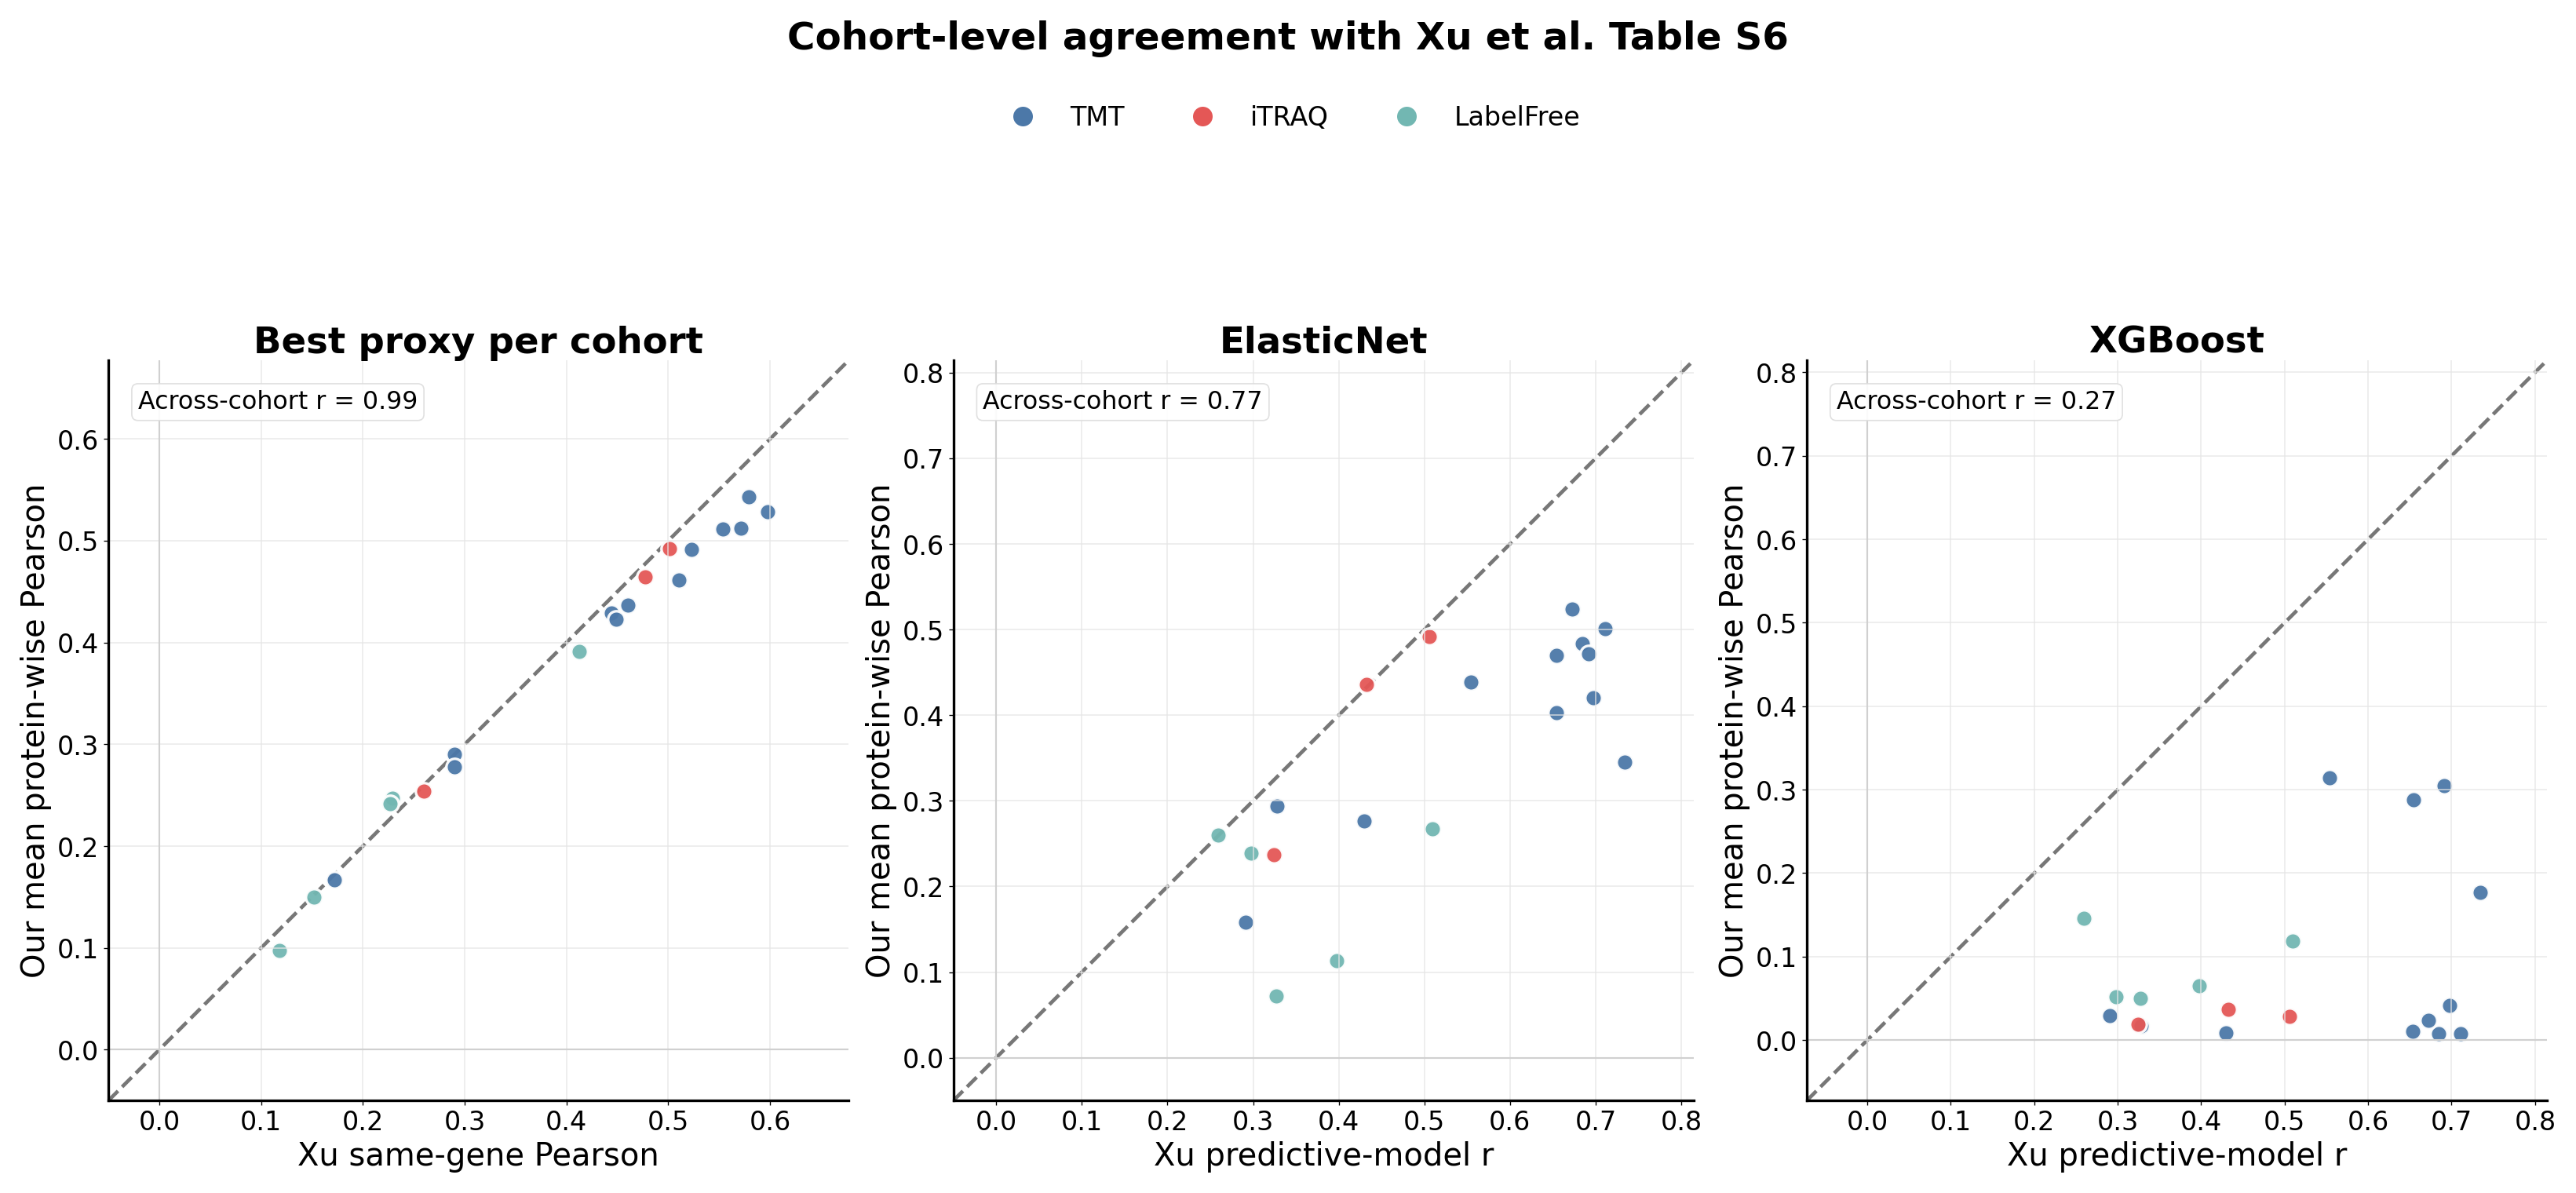

In [10]:
# Figure 2: scatter agreement across cohorts.
fig, axes = plt.subplots(1, 3, figsize=(27.0, 13.0), constrained_layout=True)

for ax, model in zip(axes, MODEL_ORDER):
    sub = plot_frame[plot_frame["model"].eq(model)].copy()
    finite = np.r_[sub["xu_reference"].to_numpy(float), sub["local_statistic"].to_numpy(float)]
    finite = finite[np.isfinite(finite)]
    lo = max(-1.0, min(-0.05, float(finite.min()) - 0.08))
    hi = min(1.0, max(0.2, float(finite.max()) + 0.08))

    for platform in ["TMT", "iTRAQ", "LabelFree"]:
        psub = sub[sub["platform"].eq(platform)]
        ax.scatter(
            psub["xu_reference"], psub["local_statistic"],
            s=165, color=PLATFORM_COLORS[platform], edgecolors="white", linewidths=2.0,
            label=platform, alpha=0.95,
        )

    ax.plot([lo, hi], [lo, hi], linestyle="--", color="#777777", linewidth=2.8, zorder=0)
    ax.axhline(0, color="#D0D0D0", linewidth=1.3)
    ax.axvline(0, color="#D0D0D0", linewidth=1.3)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(sub["xu_reference_name"].iloc[0])
    ax.set_ylabel("Our mean protein-wise Pearson")
    ax.set_title(MODEL_LABELS[model])
    ax.grid(color="#E5E5E5", linewidth=1.1, alpha=0.7)

    # Cross-cohort descriptive agreement; not an inferential model-comparison statistic.
    if len(sub) >= 3:
        agreement = np.corrcoef(sub["xu_reference"].to_numpy(float), sub["local_statistic"].to_numpy(float))[0, 1]
        ax.text(
            0.04, 0.96, f"Across-cohort r = {agreement:.2f}",
            transform=ax.transAxes, va="top", ha="left", fontsize=19,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#DDDDDD", alpha=0.9),
        )

# One shared platform legend.
handles = [
    Line2D([0], [0], marker="o", linestyle="", markerfacecolor=PLATFORM_COLORS[p],
           markeredgecolor="white", markersize=16, label=p)
    for p in ["TMT", "iTRAQ", "LabelFree"]
]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.03))
fig.suptitle("Cohort-level agreement with Xu et al. Table S6", fontsize=29, fontweight="bold", y=1.08)

_save_figure(
    fig,
    "figure_xu_vs_our_models_scatter_best_proxy_per_cohort",
    "Cohort-level agreement with Xu Table S6",
)
plt.show()


## 6. Platform-level descriptive summary

This summary averages **cohort-level** values rather than pooling samples. Error bars are 95% bootstrap intervals over cohorts within each platform. With only three iTRAQ cohorts, these intervals should be interpreted descriptively.

For the proxy series, every cohort contributes the value of whichever of Raw, Z-score, or Linear achieved the highest mean protein-wise Pearson in that cohort. Selection is **not** repeated at the platform-summary stage; it is inherited from the per-cohort selection above.


,manifest_hash,model,model_label,platform,n_cohorts,our_mean,our_ci_low,our_ci_high,xu_mean,xu_ci_low,xu_ci_high,mean_descriptive_difference,difference_ci_low,difference_ci_high,median_descriptive_difference
0,98cdc5451b903c1769428a4757a2859815a411310b36ef...,BestProxyPerCohort,Best proxy per cohort,TMT,12,0.422754,0.352724,0.481917,0.453197,0.375687,0.519270,-0.030443,-0.042521,-0.019061,-0.028669
1,98cdc5451b903c1769428a4757a2859815a411310b36ef...,BestProxyPerCohort,Best proxy per cohort,iTRAQ,3,0.403589,0.253936,0.492336,0.413027,0.260221,0.501322,-0.009438,-0.013044,-0.006285,-0.008986
2,98cdc5451b903c1769428a4757a2859815a411310b36ef...,BestProxyPerCohort,Best proxy per cohort,LabelFree,5,0.225594,0.147282,0.313244,0.227705,0.147055,0.323683,-0.002111,-0.016887,0.012664,-0.001647
3,98cdc5451b903c1769428a4757a2859815a411310b36ef...,ElasticNet,ElasticNet,TMT,12,0.398697,0.335203,0.452676,0.591698,0.503384,0.667718,-0.193001,-0.242382,-0.145832,-0.192215
4,98cdc5451b903c1769428a4757a2859815a411310b36ef...,ElasticNet,ElasticNet,iTRAQ,3,0.388034,0.236689,0.491467,0.420676,0.324377,0.505589,-0.032642,-0.087688,0.003884,-0.014122
5,98cdc5451b903c1769428a4757a2859815a411310b36ef...,ElasticNet,ElasticNet,LabelFree,5,0.190282,0.118009,0.258639,0.358235,0.288226,0.437041,-0.167953,-0.264279,-0.062224,-0.242389
6,98cdc5451b903c1769428a4757a2859815a411310b36ef...,XGBoost,XGBoost,TMT,12,0.102397,0.038078,0.175734,0.591698,0.499441,0.668463,-0.489301,-0.581049,-0.394304,-0.488882
7,98cdc5451b903c1769428a4757a2859815a411310b36ef...,XGBoost,XGBoost,iTRAQ,3,0.028071,0.018837,0.036724,0.420676,0.324377,0.505589,-0.392605,-0.476938,-0.305540,-0.395337
8,98cdc5451b903c1769428a4757a2859815a411310b36ef...,XGBoost,XGBoost,LabelFree,5,0.086274,0.053771,0.121261,0.358235,0.288226,0.442432,-0.271960,-0.345320,-0.183772,-0.277093


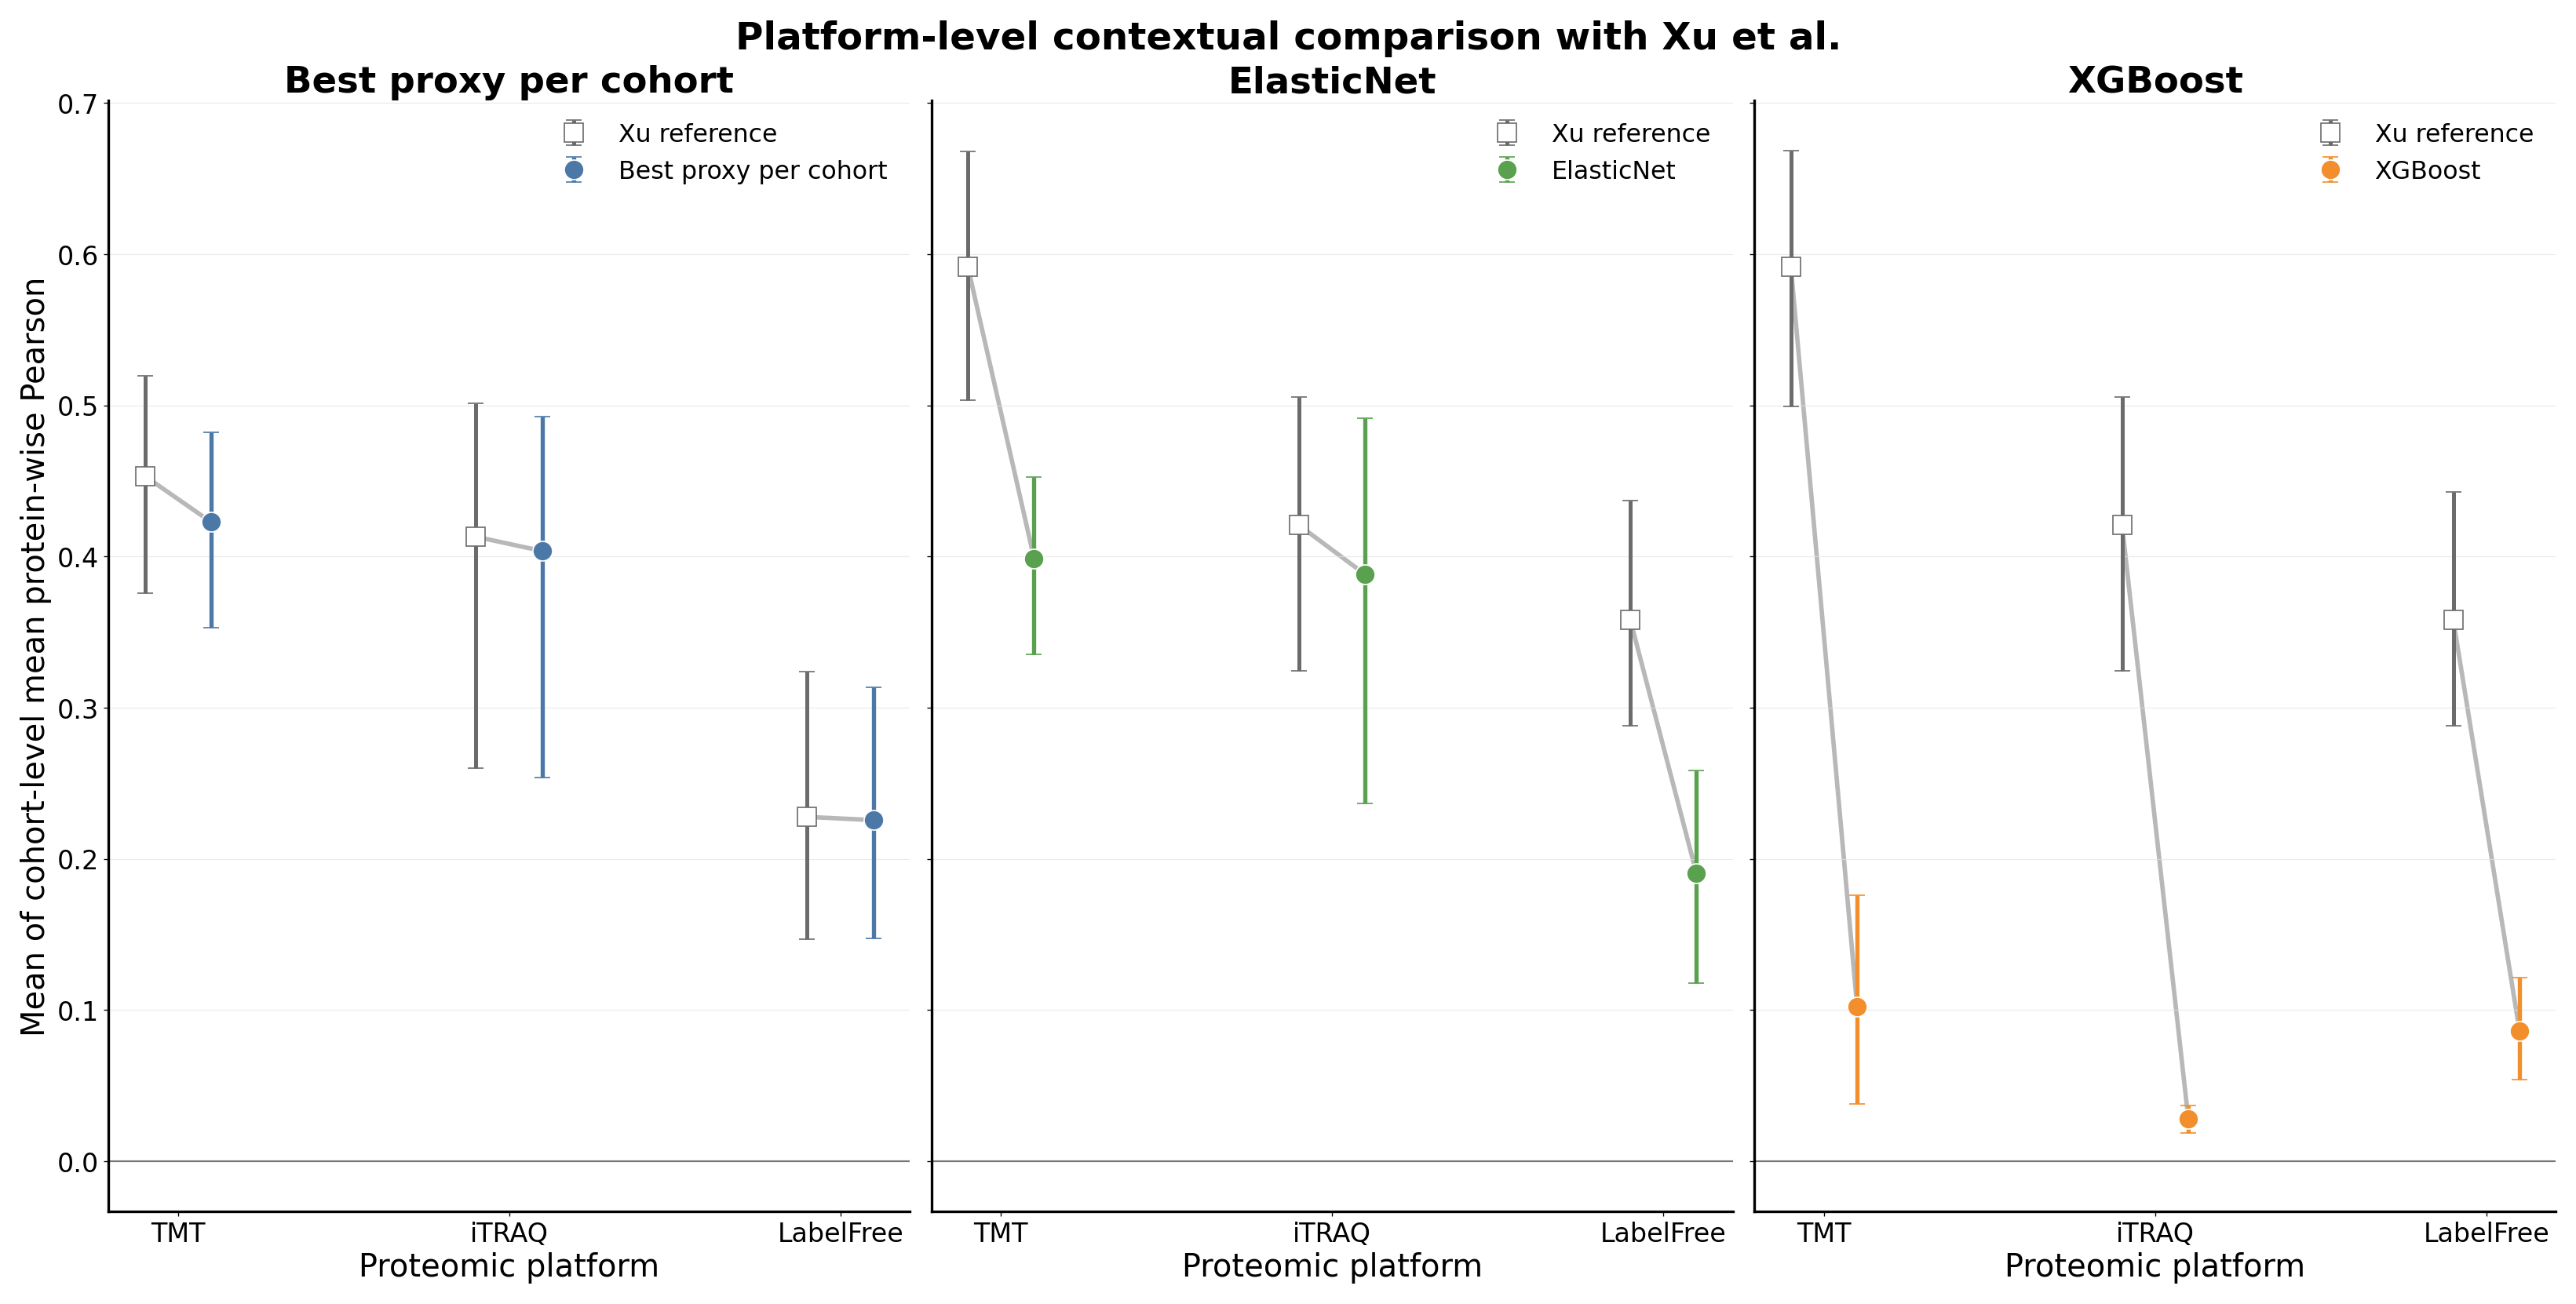

In [11]:
# Build platform-level paired summaries with cohort-bootstrap intervals.
platform_rows = []
N_BOOT_PLATFORM = int(os.environ.get("PAPER_VALIDATION_XU_PLATFORM_BOOT", "5000"))

for model_idx, model in enumerate(MODEL_ORDER):
    for platform_idx, platform in enumerate(["TMT", "iTRAQ", "LabelFree"]):
        sub = matched[(matched["model"].eq(model)) & (matched["platform"].eq(platform))].copy()
        if sub.empty:
            continue
        our_mean, our_lo, our_hi = _bootstrap_mean_ci(
            sub["local_statistic"].to_numpy(float),
            n_boot=N_BOOT_PLATFORM,
            seed=2026 + model_idx * 100 + platform_idx,
        )
        xu_mean, xu_lo, xu_hi = _bootstrap_mean_ci(
            sub["xu_reference"].to_numpy(float),
            n_boot=N_BOOT_PLATFORM,
            seed=3026 + model_idx * 100 + platform_idx,
        )
        delta_mean, delta_lo, delta_hi = _bootstrap_mean_ci(
            sub["descriptive_difference"].to_numpy(float),
            n_boot=N_BOOT_PLATFORM,
            seed=4026 + model_idx * 100 + platform_idx,
        )
        platform_rows.append({
            "manifest_hash": MANIFEST_HASH,
            "model": model,
            "model_label": MODEL_LABELS[model],
            "platform": platform,
            "n_cohorts": int(sub["cohort"].nunique()),
            "our_mean": our_mean,
            "our_ci_low": our_lo,
            "our_ci_high": our_hi,
            "xu_mean": xu_mean,
            "xu_ci_low": xu_lo,
            "xu_ci_high": xu_hi,
            "mean_descriptive_difference": delta_mean,
            "difference_ci_low": delta_lo,
            "difference_ci_high": delta_hi,
            "median_descriptive_difference": float(np.median(sub["descriptive_difference"])),
        })

platform_summary = pd.DataFrame(platform_rows)
platform_summary_path = pv.write_table(
    platform_summary,
    LAYOUT["xu"] / "xu_platform_contextual_summary",
    index=False,
)
display(platform_summary)

# Figure 3: paired dot-and-whisker platform summary.
fig, axes = plt.subplots(1, 3, figsize=(27.0, 13.5), sharey=True, constrained_layout=True)
platform_order = ["TMT", "iTRAQ", "LabelFree"]
x = np.arange(len(platform_order), dtype=float)

for ax, model in zip(axes, MODEL_ORDER):
    sub = platform_summary[platform_summary["model"].eq(model)].set_index("platform").reindex(platform_order)

    # Draw pairing lines between Xu and our means.
    for xi, xu_v, our_v in zip(x, sub["xu_mean"], sub["our_mean"]):
        ax.plot([xi - 0.10, xi + 0.10], [xu_v, our_v], color="#B8B8B8", linewidth=3.4, zorder=1)

    xu_yerr = np.vstack([
        sub["xu_mean"].to_numpy(float) - sub["xu_ci_low"].to_numpy(float),
        sub["xu_ci_high"].to_numpy(float) - sub["xu_mean"].to_numpy(float),
    ])
    our_yerr = np.vstack([
        sub["our_mean"].to_numpy(float) - sub["our_ci_low"].to_numpy(float),
        sub["our_ci_high"].to_numpy(float) - sub["our_mean"].to_numpy(float),
    ])

    ax.errorbar(
        x - 0.10, sub["xu_mean"], yerr=xu_yerr,
        fmt="s", markersize=14, color=XU_COLOR, markerfacecolor="white",
        linewidth=3.0, capsize=6, label=sub["model"].map(lambda _: "Xu reference").iloc[0],
    )
    ax.errorbar(
        x + 0.10, sub["our_mean"], yerr=our_yerr,
        fmt="o", markersize=15, color=MODEL_COLORS[model], markeredgecolor="white",
        linewidth=3.2, capsize=6, label=MODEL_LABELS[model],
    )

    ax.set_xticks(x, platform_order)
    ax.set_title(MODEL_LABELS[model])
    ax.set_xlabel("Proteomic platform")
    ax.axhline(0, color="#777777", linewidth=1.3)
    ax.grid(axis="y", color="#E2E2E2", linewidth=0.7, alpha=0.7)
    ax.legend(fontsize=19, loc="best")

axes[0].set_ylabel("Mean of cohort-level mean protein-wise Pearson")
fig.suptitle("Platform-level contextual comparison with Xu et al.", fontsize=29, fontweight="bold")
_save_figure(
    fig,
    "figure_xu_vs_our_models_platform_summary_best_proxy_per_cohort",
    "Platform-level contextual comparison with Xu",
)
plt.show()


## 7. Evaluation-universe audit

Xu's `common` count and our `matched_proteins` count answer different questions. All three proxy variants were explicitly restricted by notebook 08 to the same **paper matched-primary protein universe** within each cohort before the best proxy was chosen, so the per-cohort proxy comparison does not gain an advantage from changing the evaluated protein count across proxy variants. Xu's value comes from Xu et al.'s own analysis, so the two counts are reported side by side but are not expected to be equal.


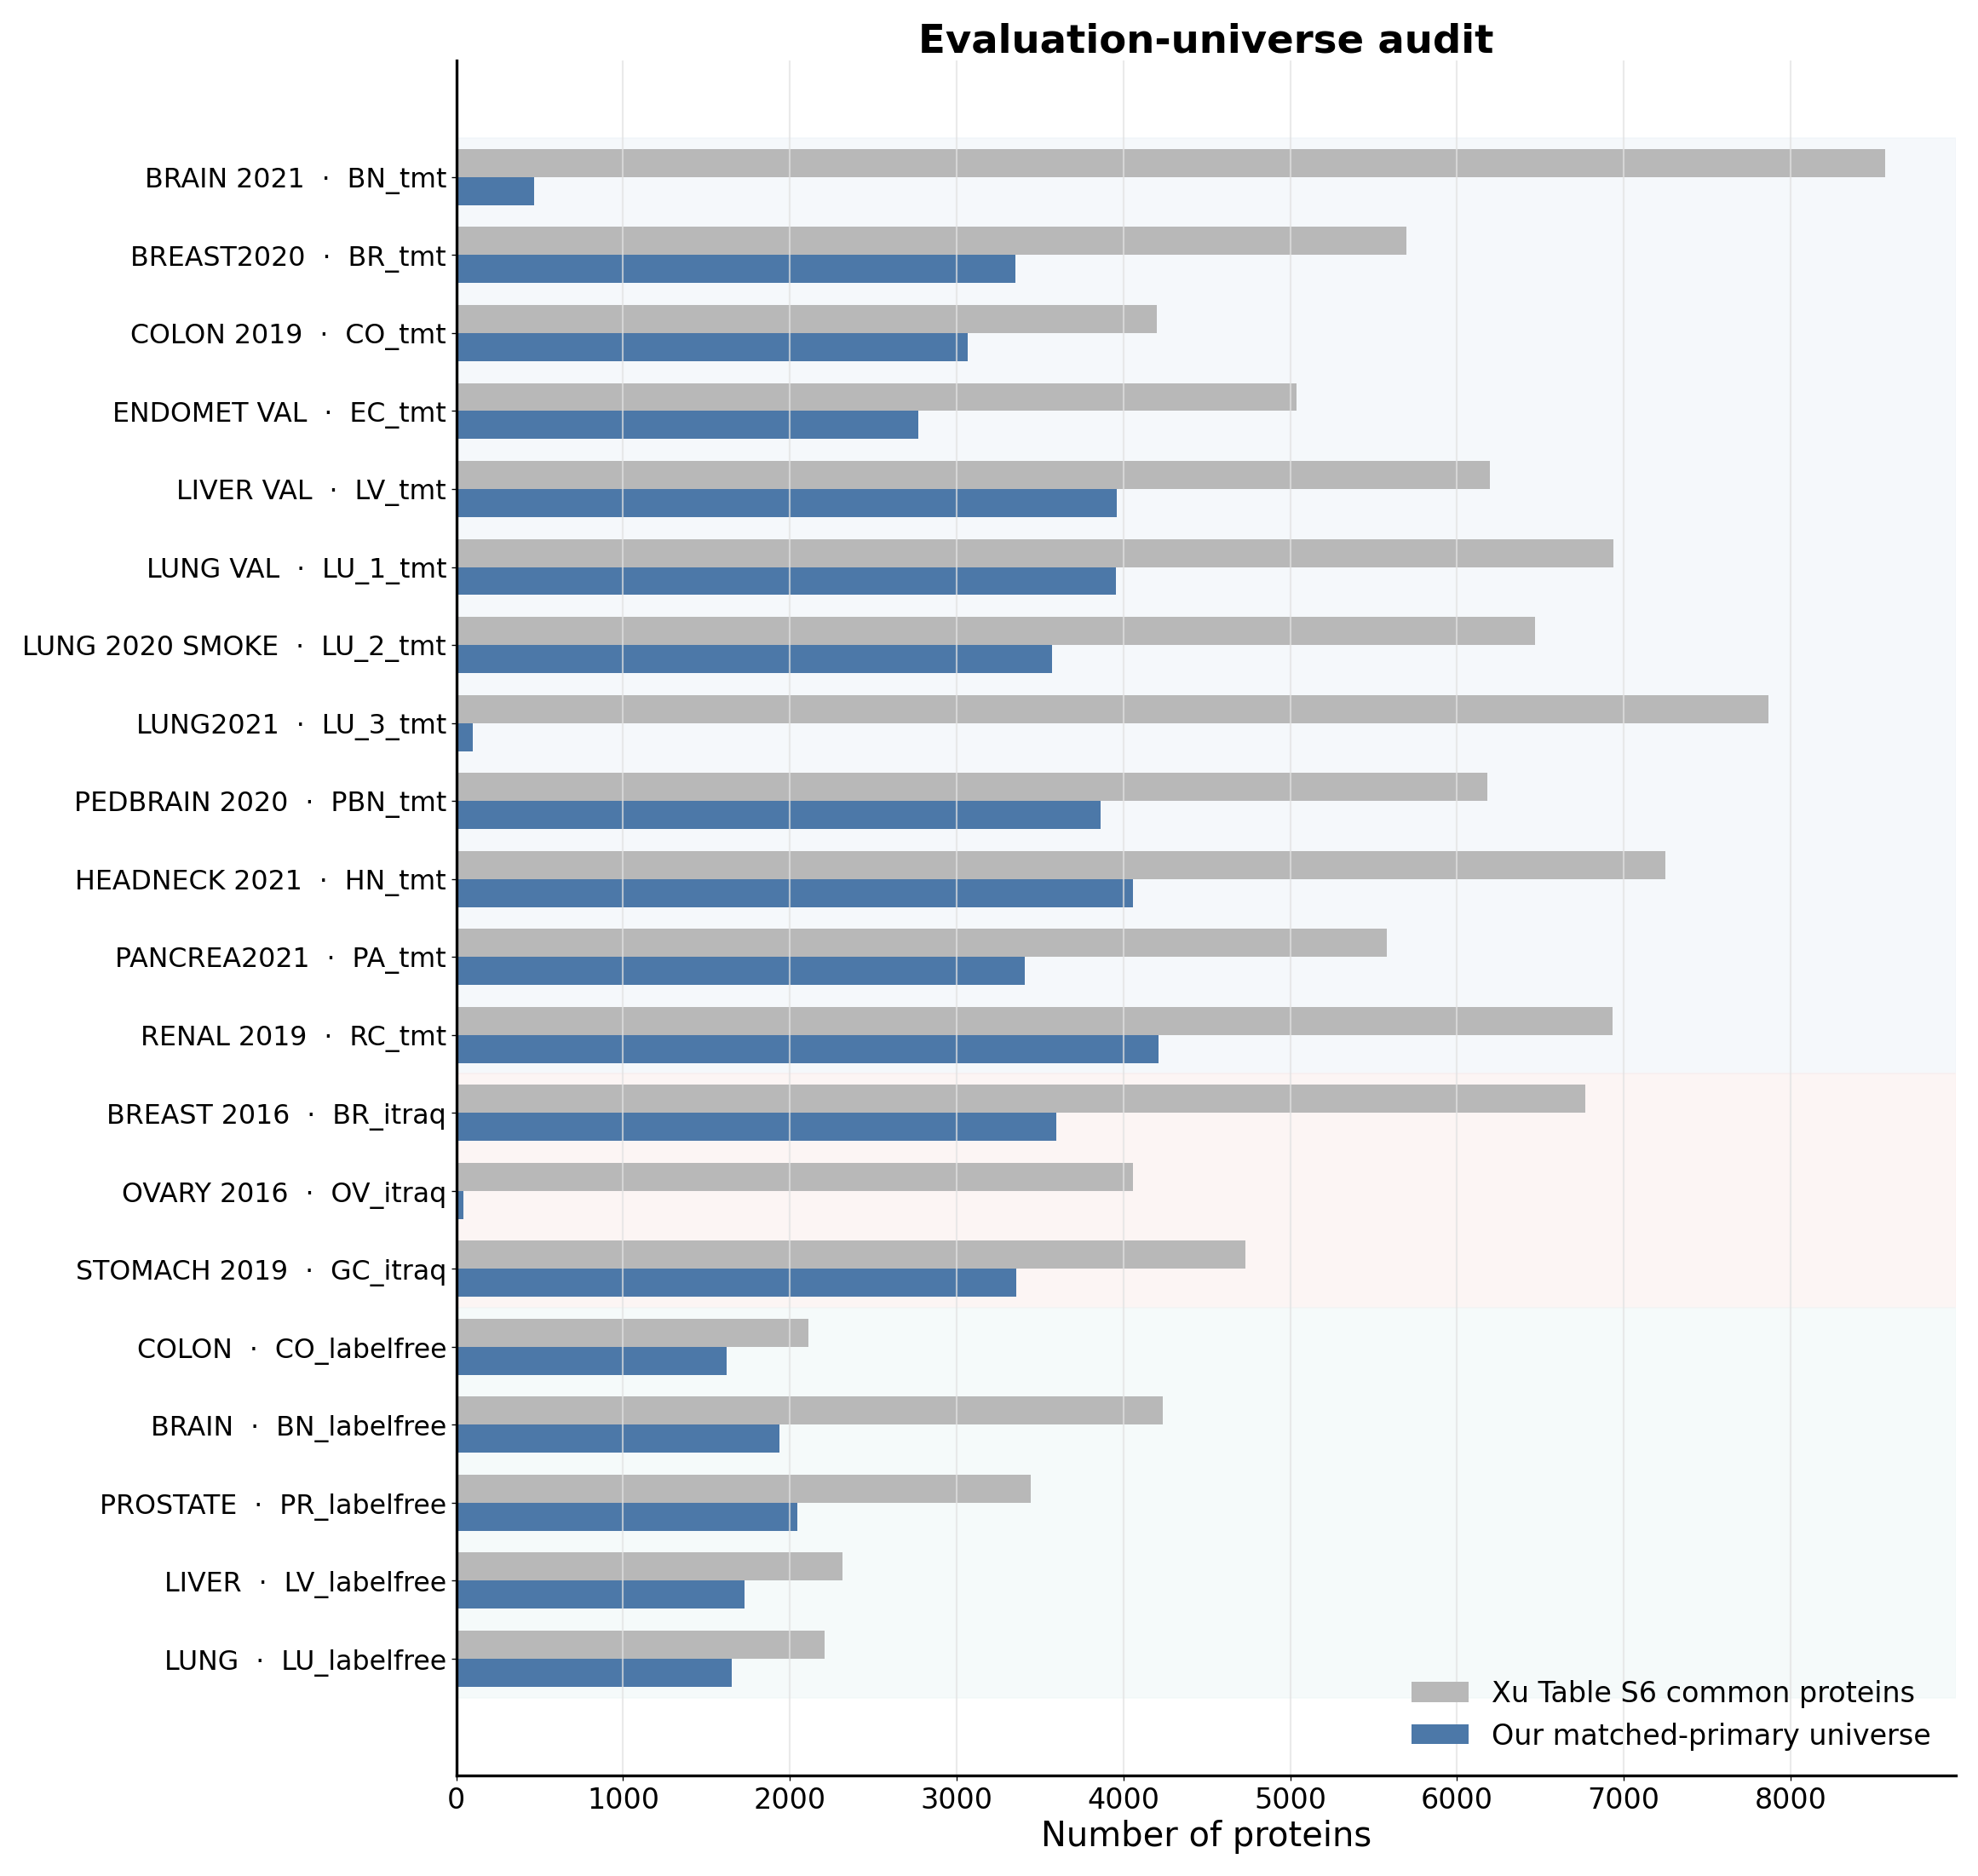

In [12]:
# Figure 4: evaluation-universe audit (supplementary/QC figure).
audit_plot = mapping_audit.copy()
audit_plot["cohort_rank"] = audit_plot["cohort"].map(cohort_rank)
audit_plot = audit_plot.sort_values("cohort_rank").set_index("cohort").reindex(cohort_order).reset_index()

y = np.arange(len(audit_plot), dtype=float)
fig, ax = plt.subplots(figsize=(19.0, 18.0), constrained_layout=True)
_apply_platform_bands(ax, cohort_order)

ax.barh(y - 0.18, audit_plot["xu_common"], height=0.36, color="#B8B8B8", label="Xu Table S6 common proteins")
ax.barh(y + 0.18, audit_plot["matched_proteins"], height=0.36, color="#4C78A8", label="Our matched-primary universe")
ax.set_yticks(y)
ax.set_yticklabels([_friendly_cohort_label(c) for c in cohort_order], fontsize=19.0)
ax.invert_yaxis()
ax.set_xlabel("Number of proteins")
ax.set_title("Evaluation-universe audit")
ax.grid(axis="x", color="#E2E2E2", linewidth=1.3, alpha=0.7)
ax.legend(loc="lower right")
_save_figure(
    fig,
    "figure_xu_evaluation_universe_audit_best_proxy_per_cohort",
    "Xu and local evaluation-universe audit",
)
plt.show()


## 8. Figure registry, summary tables, and provenance

This final cell runs only after all figures have been created, so the previous `xu_figure_registry_path` `NameError` cannot occur.


In [13]:
# Additional compact summary: one row per model, useful for manuscript drafting.
model_summary = (
    matched.groupby(["model", "model_label", "xu_reference_name"], observed=True)
    .agg(
        cohorts=("cohort", "nunique"),
        mean_our_pearson=("local_statistic", "mean"),
        median_our_pearson=("local_statistic", "median"),
        mean_xu_reference=("xu_reference", "mean"),
        median_xu_reference=("xu_reference", "median"),
        mean_descriptive_difference=("descriptive_difference", "mean"),
        median_descriptive_difference=("descriptive_difference", "median"),
        cohorts_our_above_xu=("descriptive_difference", lambda s: int((pd.to_numeric(s, errors="coerce") > 0).sum())),
    )
    .reset_index()
)
model_summary["percent_cohorts_our_above_xu"] = (
    100.0 * model_summary["cohorts_our_above_xu"] / model_summary["cohorts"].clip(lower=1)
)
model_summary["manifest_hash"] = MANIFEST_HASH
model_summary_path = pv.write_table(
    model_summary,
    LAYOUT["xu"] / "xu_model_contextual_summary",
    index=False,
)

# Registry contains vector PDF outputs only.
if not figure_paths:
    raise RuntimeError("No Xu comparison figures were created; provenance will not be written.")

# Fail early if a plotting cell was skipped or a non-PDF path slipped in.
_non_pdf = [p for p in figure_paths if Path(p).suffix.lower() != ".pdf"]
if _non_pdf:
    raise RuntimeError(f"Notebook 010 produced non-PDF figure paths: {_non_pdf}")
_missing = [p for p in figure_paths if not Path(p).exists()]
if _missing:
    raise RuntimeError(f"Notebook 010 figure files are missing: {_missing}")

xu_figure_registry = pd.DataFrame([{
    "manifest_hash": MANIFEST_HASH,
    "figure": path.name,
    "path": str(path.resolve()),
    "sha256": pv.file_sha256(path),
    "format": path.suffix.lower().lstrip("."),
} for path in figure_paths])

xu_figure_registry_path = pv.write_table(
    xu_figure_registry,
    LAYOUT["xu"] / "figure_registry",
    index=False,
)

provenance = pv.notebook_provenance(
    "010_xu_contextual_comparison_best_proxy_per_cohort_robust.ipynb",
    MANIFEST_HASH,
    {
        "cohort_summary": str((LAYOUT["tables"] / "external_cohort_primary_summary").resolve()),
        "proxy_variant_cohort_summary": str((LAYOUT["tables"] / "external_proxy_variant_cohort_summary").resolve()),
        "result_manifest_hash": RESULT_MANIFEST_HASH,
        "current_manifest_hash_at_notebook10_run": CURRENT_MANIFEST_HASH,
        "result_manifest_matches_current": bool(MANIFEST_MATCHES_CURRENT),
        "manifest_provenance_rule": "frozen notebook-8 result-table hash is authoritative for analysed results",
        "xu_workbook": str(xu_path.resolve()),
        "xu_sheet": xu_sheet,
        "local_statistic": "mean protein-wise Pearson correlation within each external cohort",
        "proxy_reference": "Xu Table S6 pearson",
        "predictor_reference": "Xu Table S6 r",
        "proxy_selection_scope": "independent selection within each of the 20 external cohorts",
        "proxy_selection_metric": "highest cohort-level mean protein-wise Pearson among Raw/Z-score/Linear",
        "proxy_candidates": PROXY_CANDIDATES,
        "proxy_selection_is_external_upper_envelope": True,
        "synthetic_proxy_model": BEST_PROXY_PER_COHORT_MODEL,
        "synthetic_proxy_label": BEST_PROXY_PER_COHORT_LABEL,
    },
    {
        "proxy_selection_audit": str(Path(proxy_selection_path).resolve()),
        "proxy_selection_counts": str(Path(proxy_selection_counts_path).resolve()),
        "proxy_candidate_global_diagnostic": str(Path(proxy_candidate_summary_path).resolve()),
        "comparison_table": str(Path(matched_path).resolve()),
        "coverage_table": str(Path(coverage_path).resolve()),
        "mapping_audit": str(Path(mapping_audit_path).resolve()),
        "platform_summary": str(Path(platform_summary_path).resolve()),
        "model_summary": str(Path(model_summary_path).resolve()),
        "figure_directory": str(FIGURE_DIR.resolve()),
        "figure_registry": str(Path(xu_figure_registry_path).resolve()),
    },
)
pv.atomic_json_dump(provenance, LAYOUT["xu"] / "notebook10_provenance.json")

print("\nModel-level descriptive summary")
display(model_summary)
print("\nFigure registry")
display(xu_figure_registry)
print("\nDirect model competition claimed:", False)
print("All 20 Xu rows matched for the per-cohort best proxy, ElasticNet, and XGBoost:", bool(coverage["complete"].all()))
print("Proxy selection: best of Raw/Z-score/Linear selected independently within each cohort")
print("Proxy selection criterion: highest cohort-level mean protein-wise Pearson")
print("External model selection used: per-cohort proxy upper envelope only; ElasticNet/XGBoost remain fixed")
print("Per-cohort proxy selection counts:")
display(proxy_selection_counts)
print("Frozen result manifest hash used for outputs:", RESULT_MANIFEST_HASH)
print("Current validation manifest hash:", CURRENT_MANIFEST_HASH)
print("Manifest hashes match:", MANIFEST_MATCHES_CURRENT)



Model-level descriptive summary


,model,model_label,xu_reference_name,cohorts,mean_our_pearson,median_our_pearson,mean_xu_reference,median_xu_reference,mean_descriptive_difference,median_descriptive_difference,cohorts_our_above_xu,percent_cohorts_our_above_xu,manifest_hash
0,BestProxyPerCohort,Best proxy per cohort,Xu same-gene Pearson,20,0.370589,0.425990,0.390798,0.446287,-0.020209,-0.017561,3,15.0,98cdc5451b903c1769428a4757a2859815a411310b36ef...
1,ElasticNet,ElasticNet,Xu predictive-model r,20,0.344994,0.373729,0.507679,0.507440,-0.162685,-0.168402,2,10.0,98cdc5451b903c1769428a4757a2859815a411310b36ef...
2,XGBoost,XGBoost,Xu predictive-model r,20,0.087218,0.039004,0.507679,0.507440,-0.420461,-0.388587,0,0.0,98cdc5451b903c1769428a4757a2859815a411310b36ef...



Figure registry


,manifest_hash,figure,path,sha256,format
0,98cdc5451b903c1769428a4757a2859815a411310b36ef...,figure_external_validation_xu_context.pdf,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,1e813c68d2fd19812e07b9a951a62d21e6a46769a6f225...,pdf
1,98cdc5451b903c1769428a4757a2859815a411310b36ef...,figure_xu_vs_our_models_scatter_best_proxy_per...,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,981cd1ea2bbacd52e043ba76b48e78b01dd703b951da35...,pdf
2,98cdc5451b903c1769428a4757a2859815a411310b36ef...,figure_xu_vs_our_models_platform_summary_best_...,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,6b7aacea8ba4f381b3fa0f680d305df93f7733d19b9c62...,pdf
3,98cdc5451b903c1769428a4757a2859815a411310b36ef...,figure_xu_evaluation_universe_audit_best_proxy...,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,91bfa723d27b493063278cf7c753e1d7208e34e0f28866...,pdf



Direct model competition claimed: False
All 20 Xu rows matched for the per-cohort best proxy, ElasticNet, and XGBoost: True
Proxy selection: best of Raw/Z-score/Linear selected independently within each cohort
Proxy selection criterion: highest cohort-level mean protein-wise Pearson
External model selection used: per-cohort proxy upper envelope only; ElasticNet/XGBoost remain fixed
Per-cohort proxy selection counts:


,proxy_model,proxy_label,selected_cohorts,mean_selected_pearson,median_selected_pearson,manifest_hash
0,RawProxy,Raw same-gene proxy,7,0.402230,0.461783,98cdc5451b903c1769428a4757a2859815a411310b36ef...
1,ZscoreProxy,Z-score same-gene proxy,13,0.353552,0.391472,98cdc5451b903c1769428a4757a2859815a411310b36ef...
2,LinearProxy,Same-gene linear proxy,0,NaN,NaN,98cdc5451b903c1769428a4757a2859815a411310b36ef...


Frozen result manifest hash used for outputs: 98cdc5451b903c1769428a4757a2859815a411310b36efcb7ddbbf347f2bce50
Current validation manifest hash: 98cdc5451b903c1769428a4757a2859815a411310b36efcb7ddbbf347f2bce50
Manifest hashes match: True
